# 부산 신항 선석 통합운영 시뮬레이션 (2025)

**흐름**: 실제 데이터(포트미스 + 터미널 선석자료) → 실제 운영 재현(A) → 모델 검증 → 시나리오 비교(A 기존 / B 인접공유 / C 전체통합) → KPI 비교 → 환적 컨테이너 연결(연결선 간격·야드 체류) → 개선안

**분석 방향(수정)**: 결과는 KPI-1~5로만 말하고, 모든 감소·증가 수치는 입력이 바뀌어도 방향이 고정된 산식(셀 28b, `min(a, max(0, G−g))` 등)으로 계산한다. 앞당김 효과는 시뮬레이션이 아니라 산식에 따른 산술적 상한으로 구분해 보고한다.

- 셀 1~10: 데이터 읽기 (선석배정 7개 터미널, 선박 제원)
- 셀 11~15: 설정, 포트미스 도착 시각 반영, 시뮬레이션 함수, 물량
- 셀 16~18: **모델 검증**과 설정 민감도
- 셀 19~22: 500회 실행과 KPI 비교
- 셀 23~27: 환적 컨테이너 연결, 체류시간, 자부두 vs 타부두 비교
- 셀 28b: **KPI 산식 정의와 단조성 검증**
- 셀 29: 야드 체류시간 감소효과(연결선 앞당김)
- 셀 30: 요약 그림
- 마지막: 요약 / 결과 / 분석 결과 / 한계 마크다운


In [1]:
#셀 1: 라이브러리와 경로 설정

import pandas as pd                          # 표(데이터프레임) 처리 라이브러리
import numpy as np                           # 숫자 계산 라이브러리
from pathlib import Path                     # 폴더·파일 경로를 다루는 도구

BASE = Path(".")                             # 노트북이 있는 폴더(프로젝트 최상위)를 기준으로 삼는다
BERTH_DIR = BASE / "data" / "berth"          # 터미널별 선석배정 파일 폴더
CONTAINER_DIR = BASE / "data" / "container"  # 컨테이너 반입·반출 파일 폴더
PORTMIS_DIR = BASE / "data" / "portmis"      # 포트미스 입출항 파일 폴더
VESSEL_DIR = BASE / "data" / "vessel"        # 선박 제원 파일 폴더
OUT_DIR = BASE / "output"                    # 결과를 저장할 폴더
OUT_DIR.mkdir(exist_ok=True)                 # output 폴더가 없으면 만든다

YEAR = 2025                                  # 분석할 연도

pd.set_option("display.width", 200)          # 표를 출력할 때 한 줄 너비를 넓힌다
pd.set_option("display.max_columns", 50)     # 열이 생략되지 않게 표시할 최대 열 수를 늘린다

for folder in [BERTH_DIR, CONTAINER_DIR, PORTMIS_DIR, VESSEL_DIR]:
    print(folder, "->", sorted(p.name for p in folder.iterdir()))

data/berth -> ['BCT_2025.xlsx', 'BNCT_2025.xlsx', 'DGT_2025.xlsx', 'HJNC_2025.xlsx', 'HPNT_2025.xls', 'PNC_2025.xlsx', 'PNIT_2025.xls']
data/container -> ['DGT_DGT.csv', 'DGT_HJNC_2025.csv', 'hjnc_hjnc.csv']
data/portmis -> ['portmis_calls.csv']
data/vessel -> ['vessel_spec_선박크기.csv']


In [2]:
# 셀 2: HJNC 선석배정 파일 읽기
hjnc_file = [p for p in BERTH_DIR.glob("*.xls*")      # berth 폴더의 엑셀 파일 중에서
             if "HJNC" in p.name.upper()]             # 이름에 HJNC가 들어간 파일을 찾는다
print(hjnc_file)                                      # 정확히 1개가 나와야 한다

hjnc_raw = pd.read_excel(hjnc_file[0], header=1)
print(hjnc_raw.shape)
print(hjnc_raw.columns.tolist())
hjnc_raw.head()

[PosixPath('data/berth/HJNC_2025.xlsx')]
(1002, 18)
['No', '선석', '항로', '모선항차', '선박명', '선사항차', '접안', '선사', '반입 시작일시', '반입 마감일시', '입항일시', '출항일시', '작업 시작일시', '작업 완료일시', '양하', '선적', 'S/H', '전배']
   No  선석    항로            모선항차                 선박명           선사항차 접안   선사           반입 시작일시           반입 마감일시              입항일시              출항일시           작업 시작일시           작업 완료일시    양하    선적  \
0   1  1B   MD3  YWDM-2024-0002           YM WISDOM      020W-021W  S  YML  2024-12-28 00:00  2024-12-31 06:00  2024-12-31 15:54  2025-01-02 23:00  2024-12-31 17:30  2025-01-02 21:46  3122  1276   
1   2  1B  SIS2  ZGHZ-2025-0001  ZHONG GU HANG ZHOU  24005W-24005W  S  TSL  2024-12-31 00:00  2025-01-02 15:00  2025-01-03 00:55  2025-01-03 22:00  2025-01-03 14:10  2025-01-03 21:42   807   514   
2   3  1B   JVH  OSWR-2025-0001   SWAN RIVER BRIDGE      105S-105S  S  ONE  2025-01-01 00:00  2025-01-03 14:00  2025-01-04 00:05  2025-01-04 11:00  2025-01-04 00:53  2025-01-04 10:59   252   444   
3   4  1B   AIS  

In [3]:
# 셀 3: 변환 도구 함수
def num(s):
    """쉼표·공백·'-'가 섞인 열을 숫자로 바꾼다. 바꿀 수 없는 값은 빈 값(NaN)이 된다."""
    cleaned = (s.astype(str)                          # 우선 모두 문자열로 바꾸고
                .str.replace(",", "")                 # 천 단위 쉼표를 없애고
                .str.strip()                          # 앞뒤 공백을 지우고
                .replace({"null": None, "-": None, "nan": None}))   # 값이 없다는 뜻의 글자는 빈 값으로
    return pd.to_numeric(cleaned, errors="coerce")    # 숫자로 변환 (실패하면 NaN)


def dt(s):
    """문자열 열을 날짜·시각으로 바꾼다. 바꿀 수 없는 값은 빈 값(NaT)이 된다."""
    return pd.to_datetime(s.replace({"-": None, "null": None}), errors="coerce")

In [4]:
# 셀 4: HJNC를 공통 형식으로 변환
def load_hjnc(raw):
    """HJNC 원본 표를 공통 열 이름의 표로 바꾼다."""
    return pd.DataFrame({
        "terminal": "HJNC",                           # 터미널 이름 (모든 행에 같은 값)
        "berth": raw["선석"].astype(str),              # 선석 번호
        "vessel": raw["선박명"],                       # 선박 이름
        "voyage": raw["모선항차"],                     # 모선 항차
        "carrier": raw["선사"],                        # 선사
        "route": raw["항로"],                          # 항로
        "gate_open": dt(raw["반입 시작일시"]),         # 컨테이너 반입 시작(게이트 오픈) 시각
        "gate_cutoff": dt(raw["반입 마감일시"]),       # 반입 마감 시각
        "etb": dt(raw["입항일시"]),                    # 접안 시각 (HJNC는 '입항일시' 열이 접안 시각)
        "etd": dt(raw["출항일시"]),                    # 출항 시각
        "work_start": dt(raw["작업 시작일시"]),        # 하역 작업 시작
        "work_end": dt(raw["작업 완료일시"]),          # 하역 작업 완료
        "discharge": num(raw["양하"]),                 # 양하(내리는) 수량
        "load": num(raw["선적"]),                      # 적하(싣는) 수량
        "shift": num(raw["S/H"]),                      # 선내 이동(shift) 수량
        "status": None,                               # HJNC에는 상태 열이 없다
    })

hjnc = load_hjnc(hjnc_raw)                            # 변환 실행
print(hjnc.shape)                                     # 행 수 확인
print(hjnc.dtypes)                                    # 각 열이 날짜·숫자로 잘 바뀌었는지 확인
print(hjnc[["etb", "etd"]].isna().sum())              # 접안·출항 시각이 비어 있는 행 수 (0에 가까워야 한다)
print(hjnc["etb"].min(), "~", hjnc["etb"].max())      # 접안 시각의 범위 (2025년이어야 한다)
hjnc.head()

(1002, 16)
terminal                  str
berth                     str
vessel                    str
voyage                    str
carrier                   str
route                     str
gate_open      datetime64[us]
gate_cutoff    datetime64[us]
etb            datetime64[us]
etd            datetime64[us]
work_start     datetime64[us]
work_end       datetime64[us]
discharge               int64
load                    int64
shift                   int64
status                 object
dtype: object
etb    0
etd    0
dtype: int64
2024-12-30 22:30:00 ~ 2025-12-31 08:40:00
  terminal berth              vessel          voyage carrier route  gate_open         gate_cutoff                 etb                 etd          work_start            work_end  discharge  load  \
0     HJNC    1B           YM WISDOM  YWDM-2024-0002     YML   MD3 2024-12-28 2024-12-31 06:00:00 2024-12-31 15:54:00 2025-01-02 23:00:00 2024-12-31 17:30:00 2025-01-02 21:46:00       3122  1276   
1     HJNC    1B  ZHONG GU

In [5]:
# 셀 5: HPNT, PNIT (HTML 형식의 .xls)
import io                                             # 문자열을 파일처럼 다루는 도구

def find_one(keyword):
    """berth 폴더에서 이름에 keyword가 들어간 파일을 정확히 하나 찾는다."""
    hits = [p for p in BERTH_DIR.glob("*.xls*") if keyword.upper() in p.name.upper()]
    assert len(hits) == 1, f"{keyword} 파일이 {len(hits)}개: {hits}"   # 0개나 2개 이상이면 멈춘다
    return hits[0]

def read_html_table(path):
    """확장자는 .xls지만 내용은 HTML 표인 파일에서 가장 큰 표를 읽는다."""
    text = open(path, encoding="utf-8").read()        # 파일을 글자로 읽는다
    tables = pd.read_html(io.StringIO(text), flavor="lxml")   # HTML 안의 표를 모두 찾아서
    return max(tables, key=len)                       # 행이 가장 많은 표를 고른다

hpnt_raw = read_html_table(find_one("HPNT"))          # HPNT 원본
pnit_raw = read_html_table(find_one("PNIT"))          # PNIT 원본
print("HPNT", hpnt_raw.shape, hpnt_raw.columns.tolist())   # 크기와 열 이름 확인
print("PNIT", pnit_raw.shape, pnit_raw.columns.tolist())


def load_hpnt(raw):
    return pd.DataFrame({
        "terminal": "HPNT", "berth": raw["선석"].astype(str), "vessel": raw["선명"], "voyage": raw["모선항차"],
        "carrier": raw["선사"], "route": raw["ROUTE"],
        "gate_open": dt(raw["반입시작일시"]), "gate_cutoff": dt(raw["반입마감시한"]),
        "etb": dt(raw["접안(예정)일시"]), "etd": dt(raw["출항(예정)일시"]),   # 접안·출항 시각
        "work_start": pd.NaT, "work_end": pd.NaT,     # HPNT에는 작업 시각 열이 없다
        "discharge": num(raw["양하"]), "load": num(raw["적하"]), "shift": num(raw["Shift"]),
        "status": raw["상태"]})

def load_pnit(raw):
    return pd.DataFrame({
        "terminal": "PNIT", "berth": raw["선석"].astype(str), "vessel": raw["선명"], "voyage": raw["모선항차"],
        "carrier": raw["선사"], "route": raw["ROUTE"],
        "gate_open": pd.NaT,                          # PNIT에는 반입 시작 열이 없다
        "gate_cutoff": dt(raw["반입마감시한"]),
        "etb": dt(raw["접안(예정)일시"]), "etd": dt(raw["출항(예정)일시"]),
        "work_start": pd.NaT, "work_end": pd.NaT,
        "discharge": num(raw["양하"]), "load": num(raw["적하"]), "shift": num(raw["Shift"]),
        "status": raw["상태"]})

hpnt = load_hpnt(hpnt_raw)
pnit = load_pnit(pnit_raw)
for name, t in [("HPNT", hpnt), ("PNIT", pnit)]:     # 두 터미널을 같은 방식으로 점검
    print(name, t.shape, "접안 결측", t["etb"].isna().sum(), "|", t["etb"].min(), "~", t["etb"].max())

HPNT (887, 15) ['선석', '선사', '모선항차', '선사항차', '선명', 'ROUTE', '반입시작일시', '반입마감시한', '접안(예정)일시', '출항(예정)일시', '양하', '적하', 'Shift', 'AMP', '상태']
PNIT (699, 15) ['선석', '선사', '모선항차', '선사항차', 'Head (Bridge) Stern', '선명', 'ROUTE', '반입마감시한', '접안(예정)일시', '출항(예정)일시', '양하', '적하', 'Shift', 'AMP', '상태']
HPNT (887, 16) 접안 결측 0 | 2024-12-31 07:06:00 ~ 2025-12-31 23:36:00
PNIT (699, 16) 접안 결측 0 | 2024-12-30 01:35:00 ~ 2025-12-31 12:30:00


In [6]:
# 셀 6: BCT, BNCT
bct_raw = pd.read_excel(find_one("BCT"))              # BCT 원본 (BNCT 파일 이름에도 'CT'가 있지만 'BCT'는 겹치지 않는다)
bnct_raw = pd.read_excel(find_one("BNCT"))            # BNCT 원본
print("BCT", bct_raw.shape, bct_raw.columns.tolist())
print("BNCT", bnct_raw.shape, bnct_raw.columns.tolist())


def load_bct(raw):
    return pd.DataFrame({
        "terminal": "BCT", "berth": raw["선석"].astype(str), "vessel": raw["모선명"], "voyage": raw["모선/항차"],
        "carrier": raw["선사"], "route": raw["ROUTE"],
        "gate_open": pd.NaT, "gate_cutoff": dt(raw["CCT"]),     # CCT = 반입 마감 시각
        "etb": dt(raw["접안예정시간(ETB)"]), "etd": dt(raw["출항예정시간(ETD)"]),
        "work_start": pd.NaT, "work_end": pd.NaT,
        "discharge": num(raw["양하"]), "load": num(raw["적하"]), "shift": num(raw["이적"]),
        "status": raw["상태"]})

def load_bnct(raw):
    c = list(raw.columns)                             # BNCT는 열 이름이 길어서 위치(순서)로 읽는다
    wl = raw[c[7]].astype(str).str.split("/", expand=True)   # '양하/적하/이적'으로 합쳐진 열을 나눈다
    return pd.DataFrame({
        "terminal": "BNCT", "berth": raw[c[0]].astype(str),
        "vessel": raw[c[3]].astype(str).str.replace(r"\(.*\)$", "", regex=True).str.strip(),  # 선박명 뒤 (항로) 제거
        "voyage": raw[c[2]].astype(str).str.extract(r"^(\S+)")[0],
        "carrier": raw[c[1]],
        "route": raw[c[3]].astype(str).str.extract(r"\(([^()]*)\)$")[0],     # 괄호 안 글자를 항로로
        "gate_open": pd.NaT, "gate_cutoff": dt(raw[c[4]]),
        "etb": dt(raw[c[5]]), "etd": dt(raw[c[6]]),
        "work_start": pd.NaT, "work_end": pd.NaT,
        "discharge": num(wl[0]), "load": num(wl[1]), "shift": num(wl[2]),
        "status": raw[c[8]]})

bct = load_bct(bct_raw)
bnct = load_bnct(bnct_raw)
for name, t in [("BCT", bct), ("BNCT", bnct)]:
    print(name, t.shape, "접안 결측", t["etb"].isna().sum(), "|", t["etb"].min(), "~", t["etb"].max())
bnct.head()                                           # BNCT는 열 분리가 맞는지 눈으로 확인

BCT (1044, 18) ['No', '선석', '선사', '모선/항차', '입항', '출항', 'CCT', '접안예정시간(ETB)', '출항예정시간(ETD)', '양하', '적하', '이적', '모선명', 'ROUTE', '전배TML', '검역', '줄잡이업체', '상태']
BNCT (987, 9) ['선석', '선사', '모선항차(선사항차)\nHead (Bridge) Stern', '선명\n(ROUTE)', '반입마감시한', '접안(예정)일시', '출항(예정)일시', '작업량\n양하 / 적하 / Shift', '상태']
BCT (1044, 16) 접안 결측 0 | 2024-12-31 20:00:00 ~ 2025-12-30 18:00:00
BNCT (987, 16) 접안 결측 0 | 2024-12-30 14:24:00 ~ 2025-12-31 23:24:00
  terminal berth            vessel   voyage carrier  route gate_open         gate_cutoff                 etb                 etd work_start work_end  discharge  load  shift    status
0     BNCT  1(S)    PRESIDENT BUSH  APBU001     APL   EX1E       NaT 2024-12-30 19:41:00 2024-12-31 08:35:00 2025-01-01 05:55:00        NaT      NaT        259   911     12  DEPARTED
1     BNCT  4(P)  CMA CGM ALMAVIVA  CMAV005     CMA  PE3OA       NaT 2024-12-30 17:00:00 2024-12-31 04:18:00 2025-01-01 07:00:00        NaT      NaT        850  1351      0  DEPARTED
2     BNCT  3(S)    

In [7]:
 # 셀 7: PNC, DGT (시트 이름으로 읽기)
pnc_raw = pd.read_excel(find_one("PNC"), sheet_name="2025 선석배정현황")   # PNC: 여러 시트 중 선석배정 시트만 읽는다
dgt_raw = pd.read_excel(find_one("DGT"), sheet_name="2025 선석배정현황")   # DGT: 같은 이름의 시트
print("PNC", pnc_raw.shape, pnc_raw.columns.tolist())
print("DGT", dgt_raw.shape, dgt_raw.columns.tolist())


def load_pnc(raw):
    return pd.DataFrame({
        "terminal": "PNC", "berth": raw["선석"].astype(str), "vessel": raw["모선명"], "voyage": raw["모선코드"],
        "carrier": raw["운항선사"], "route": raw["항로"],
        "gate_open": pd.NaT, "gate_cutoff": dt(raw["반입마감일시"]),      # PNC는 반입 시작 열이 없다
        "etb": dt(raw["접안(예정)일시"]), "etd": dt(raw["출항(예정)일시"]),
        "work_start": pd.NaT, "work_end": pd.NaT,
        "discharge": num(raw["양하수량"]), "load": num(raw["선적수량"]), "shift": num(raw["Shift"]),
        "status": None})

def load_dgt(raw):
    c = list(raw.columns)                             # DGT는 일부 열을 위치로 읽는다
    wl = raw[c[12]].astype(str).str.split("/", expand=True)   # 13번째 열: '양하/적하/이적'이 합쳐져 있다
    return pd.DataFrame({
        "terminal": "DGT", "berth": raw["선석"].astype(str), "vessel": raw["모선명"], "voyage": raw[c[2]],
        "carrier": raw["선사코드"], "route": raw["항로"],
        "gate_open": dt(raw["반입시작시간"]), "gate_cutoff": dt(raw["반입마감시간"]),
        "etb": dt(raw["접안예정일시"]), "etd": dt(raw["출항예정일시"]),
        "work_start": dt(raw["작업시작시간"]), "work_end": dt(raw["작업완료시간"]),
        "discharge": num(wl[0]), "load": num(wl[1]), "shift": num(wl[2]),
        "status": raw["상태"]})

pnc = load_pnc(pnc_raw)
dgt = load_dgt(dgt_raw)
for name, t in [("PNC", pnc), ("DGT", dgt)]:
    print(name, t.shape, "접안 결측", t["etb"].isna().sum(), "|", t["etb"].min(), "~", t["etb"].max())
dgt.head()                                            # DGT는 양하/적하 분리가 맞는지 확인

PNC (1385, 17) ['No.', '모선명', '모선코드', '선사항차', '운항선사', '항로', '접안방향', '접안(예정)일시', '출항(예정)일시', '선석', '반입마감일시', '양하수량', '선적수량', 'Shift', '줄잡이업체', '작업서류', '업데이트일시']
DGT (1050, 14) ['선석', '선사코드', '모선항차(선사항차)', '모선명', '항로', '반입시작시간', '반입마감시간', '접안예정일시', '출항예정일시', '작업시작시간', '작업완료시간', 'Head (Bridge) Stern', '작업량\n양하/적하/Shift', '상태']
PNC (1385, 16) 접안 결측 0 | 2025-01-01 04:00:00 ~ 2025-12-31 20:00:00
DGT (1050, 16) 접안 결측 0 | 2025-01-01 02:00:00 ~ 2025-12-31 14:00:00
  terminal  berth           vessel                               voyage carrier route  gate_open         gate_cutoff                 etb                 etd work_start work_end  discharge  load  \
0      DGT  B2(P)  PORT VILA CHIEF          SWPV-004/2024 (2410N/2501S)     SWI   SWL 2024-12-28 2024-12-31 14:00:00 2025-01-01 02:00:00 2025-01-01 19:00:00        NaT      NaT        NaN   NaN   
1      DGT  B1(P)      REN JIAN 20          SCRJ-003/2024 (2409E/2409E)     SML  HJNC 2024-12-28 2024-12-31 20:00:00 2025-01-01 08:00:00 2025-01-0

In [8]:
# 셀 8: 7개 터미널 합치기와 2025년 필터
berth_all = pd.concat([hjnc, hpnt, pnit, bct, bnct, pnc, dgt], ignore_index=True)   # 7개 표를 위아래로 이어 붙인다
print("합친 행 수:", len(berth_all))

berth_all = berth_all.dropna(subset=["etb", "etd"])   # 접안·출항 시각이 없으면 시뮬레이션에 쓸 수 없어 제외
berth_all = berth_all[berth_all["etb"].dt.year == YEAR].copy()   # 2025년 접안 건만 남긴다
berth_all = berth_all.reset_index(drop=True)          # 행 번호를 0부터 다시 매긴다
print("정리 후 행 수:", len(berth_all))               # 이전 분석에서는 약 7,042건이었다

summary = berth_all.groupby("terminal").agg(          # 터미널별 요약
    호출수=("vessel", "size"),
    첫접안=("etb", "min"), 마지막접안=("etb", "max"),
    평균점유h=("etd", lambda s: 0))                     # 자리표시 (아래에서 계산)
summary["평균점유h"] = (berth_all["etd"] - berth_all["etb"]).dt.total_seconds().div(3600).groupby(berth_all["terminal"]).mean().round(1)
print(summary)

print("\n열별 결측률(%)")
cols = ["gate_open", "gate_cutoff", "etb", "etd", "work_start", "work_end", "discharge", "load"]
print((berth_all[cols].isna().groupby(berth_all["terminal"]).mean() * 100).round(0))

berth_all.to_csv(OUT_DIR / "berth_2025.csv", index=False, encoding="utf-8-sig")   # 결과 저장 (한글 깨짐 방지 인코딩)

합친 행 수: 7054
정리 후 행 수: 7042
           호출수                 첫접안               마지막접안  평균점유h
terminal                                                     
BCT       1043 2025-01-01 02:00:00 2025-12-30 18:00:00   18.6
BNCT       984 2025-01-01 08:30:00 2025-12-31 23:24:00   21.8
DGT       1050 2025-01-01 02:00:00 2025-12-31 14:00:00   16.4
HJNC       999 2025-01-02 09:10:00 2025-12-31 08:40:00   20.8
HPNT       885 2025-01-01 09:00:00 2025-12-31 23:36:00   21.7
PNC       1385 2025-01-01 04:00:00 2025-12-31 20:00:00   28.7
PNIT       696 2025-01-01 03:40:00 2025-12-31 12:30:00   32.7

열별 결측률(%)
          gate_open  gate_cutoff  etb  etd  work_start  work_end  discharge  load
terminal                                                                         
BCT           100.0          0.0  0.0  0.0       100.0     100.0        0.0   0.0
BNCT          100.0          0.0  0.0  0.0       100.0     100.0        0.0   0.0
DGT             0.0          0.0  0.0  0.0        69.0      69.0       69.0

In [9]:
# 셀 9: 선박 제원 읽기
spec_raw = pd.read_csv(VESSEL_DIR / "vessel_spec_선박크기.csv", encoding="utf-8-sig")   # 선박 제원 csv
print(spec_raw.shape)                                 # 1,577행이어야 한다
print(spec_raw.columns.tolist())                      # 열 이름 확인

def name_key(s):
    """선박명 비교용 키: 대문자로 바꾸고 영문자·숫자만 남긴다 (공백·기호 차이를 없앤다)."""
    return s.astype(str).str.upper().str.replace(r"[^A-Z0-9]", "", regex=True)

spec = pd.DataFrame({
    "key": name_key(spec_raw["선박명(엑셀 기재)"]),     # 연결에 쓸 선박명 키
    "LOA": spec_raw["길이 LOA(m)"],                    # 선박 길이(m)
    "beam": spec_raw["폭(m)"],                         # 선박 폭(m)
    "GT": spec_raw["GT"],                              # 총톤수
    "DWT": spec_raw["DWT"],                            # 재화중량톤수
})
print("길이가 있는 선박:", spec["LOA"].notna().sum(), "/", len(spec))   # 1,521 / 1,577 이어야 한다

dup = spec["key"].duplicated(keep=False)              # 키가 같은 선박이 여러 개인지
print("키가 겹치는 행:", dup.sum())                     # 겹치면 연결할 때 행이 늘어날 수 있다
spec = spec.dropna(subset=["LOA"]).drop_duplicates("key")   # 길이가 있는 것만, 같은 키는 하나만 남긴다
print("사용할 제원:", len(spec))
spec.describe()                                       # 길이·폭 분포 확인 (비정상 값 점검)

(1577, 13)
['선박명(엑셀 기재)', '출현 터미널', '선종(VesselFinder)', '건조연도', 'GT', 'DWT', '길이 LOA(m)', '폭(m)', 'VesselFinder 검색명', '비고', 'IMO', '검증상태', '출처']
길이가 있는 선박: 1521 / 1577
키가 겹치는 행: 0
사용할 제원: 1521
               LOA         beam             GT            DWT
count  1521.000000  1521.000000    1519.000000    1521.000000
mean    296.325943    41.961019   91366.874259  104033.883235
std      71.760917     9.513432   53867.236699   58707.129862
min      89.000000    15.000000    3203.000000    4759.000000
25%     260.000000    32.200000   47552.500000   57627.000000
50%     304.000000    43.000000   91023.000000  103518.000000
75%     364.000000    48.000000  140096.000000  142411.000000
max     400.000000    62.000000  236184.000000  281456.000000


In [10]:
# 셀 10: 선석배정 표에 길이 붙이기
berth = berth_all.copy()                              # 원본은 그대로 두고 복사본에 붙인다
berth["key"] = name_key(berth["vessel"])              # 선석배정 표에도 같은 방식으로 키를 만든다

n_before = len(berth)                                 # 연결 전 행 수
berth = berth.merge(spec, on="key", how="left")       # 키로 연결 (제원에 없으면 길이는 빈 값)
assert len(berth) == n_before, "연결하면서 행이 늘었습니다 (키 중복 확인)"   # 행 수가 변하면 멈춘다
berth = berth.drop(columns="key")

g = berth.groupby("terminal")["LOA"]                  # 터미널별 길이 통계
print(pd.DataFrame({
    "호출": g.size(),
    "길이 매칭률(%)": (g.count() / g.size() * 100).round(1),
    "중앙값(m)": g.median().round(0),
    "95%(m)": g.quantile(.95).round(0),
    "최대(m)": g.max().round(0),
}))
print("\n길이가 없는 호출:", berth["LOA"].isna().sum(), "건")
print(berth.loc[berth["LOA"].isna(), "vessel"].value_counts().head(10))   # 길이를 못 붙인 선박 상위 10개

berth.to_csv(OUT_DIR / "berth_2025_loa.csv", index=False, encoding="utf-8-sig")   # 결과 저장

            호출  길이 매칭률(%)  중앙값(m)  95%(m)  최대(m)
terminal                                        
BCT       1043       96.5   148.0   366.0  400.0
BNCT       984       95.7   300.0   366.0  399.0
DGT       1050       89.8   180.0   334.0  369.0
HJNC       999       99.3   272.0   368.0  400.0
HPNT       885       98.6   272.0   366.0  400.0
PNC       1385       94.1   300.0   400.0  400.0
PNIT       696       98.1   330.0   366.0  399.0

길이가 없는 호출: 300 건
vessel
DREDGING                 40
SONG YUN HE              30
HE LE                    22
ZHONG ZHOU CHANG HONG    18
ANDONG 68                18
GLOBAL NUBIRA            11
PACIFIC CARRIER          11
HT HONOROR                9
VANTAGE                   8
VLADIVOSTOK               7
Name: count, dtype: int64


In [11]:
# 셀 11: 터미널 시설, 시나리오, 운영 규칙 설정
TERMINALS = {                                         # 터미널별 선석 수와 안벽 길이(m), 부산항만공사 시설현황 기준
    "PNIT": {"berths": 3, "quay_m": 1200},
    "PNC":  {"berths": 5, "quay_m": 2000},
    "HJNC": {"berths": 4, "quay_m": 1100},
    "HPNT": {"berths": 3, "quay_m": 1150},
    "BNCT": {"berths": 4, "quay_m": 1400},
    "BCT":  {"berths": 3, "quay_m": 1050},
    "DGT":  {"berths": 3, "quay_m": 1050},            # DGT 안벽은 1,050m로 확정
}
CAPACITY_KTEU = {"PNIT": 2090, "PNC": 3790, "HJNC": 2310, "HPNT": 1930,
                 "BNCT": 2440, "BCT": 1950, "DGT": 1950}   # 연간 하역능력(천TEU), 부산항만공사 시설현황
ARTICLE_UTIL = {"PNIT": 146, "PNC": 136, "HJNC": 127, "HPNT": 131,
                "BNCT": 99, "BCT": 87, "DGT": 57}          # 기사에 나온 터미널별 처리율(%), 모델 검증 비교용
BOX_TO_TEU = 1.7                                      # 박스 수 -> TEU 환산 (기사 처리율과 맞춰 구한 값)
DGT_ARTICLE_KTEU = 92 * 12                            # DGT 연간 물량 기사 값(월 9.2만TEU x 12 = 천TEU), 결측이 많은 DGT 물량 보정용

# 인접 터미널 (부두 배치 기준, 서로 이웃한 터미널)
NEIGHBORS = {
    "PNC":  ["HJNC", "PNIT"],
    "HJNC": ["PNC", "DGT"],
    "DGT":  ["HJNC", "BCT"],
    "BCT":  ["DGT", "BNCT"],
    "BNCT": ["BCT", "HPNT"],
    "HPNT": ["BNCT", "PNIT"],
    "PNIT": ["PNC", "HPNT"],
}
bad = [(a, b) for a, nb in NEIGHBORS.items() for b in nb if a not in NEIGHBORS[b]]   # 서로 이웃인지 대칭 확인
print("비대칭 쌍:", bad)                              # 빈 목록 []이어야 한다

SCENARIOS = {                                         # 시나리오: 터미널 -> 접안에 쓸 수 있는 터미널 후보 목록
    "A_기존(터미널별)": {t: [t] for t in TERMINALS},               # A: 자기 터미널만
    "B_인접공유": {t: [t] + NEIGHBORS[t] for t in TERMINALS},      # B: 자기 + 인접 터미널
    "C_통합(신항 전체)": {t: list(TERMINALS) for t in TERMINALS},  # C: 7개 터미널 모두
}

LOA_MARGIN = 1.0      # 선박이 안벽에서 차지하는 길이 = 선박 길이 x 이 값
CHANGEOVER_H = 0.0    # 앞 배가 나간 뒤 다음 배가 접안하기까지 간격(시간)
BERTH_LIMIT = False   # True면 터미널의 동시 접안 척수를 선석 수 이하로 제한한다
SEED = 20250101       # 난수 시드 (같은 결과가 재현되도록 고정)


비대칭 쌍: []


In [12]:
# 셀 12: 시뮬레이션 입력표 만들기 (포트미스 실제 입항 시각 반영)
calls = berth.copy()                                  # 2단계 결과(길이가 붙은 선석배정 표)를 복사
pm = pd.read_csv(PORTMIS_DIR / "portmis_calls.csv", parse_dates=["etb", "portmis_in"])   # 포트미스와 매칭된 호출 표 (유형, 실제 입항 시각)
calls = calls.merge(pm, on=["terminal", "vessel", "voyage", "etb"], how="left")          # 선박 키로 연결 (매칭 안 된 호출은 빈 값)

# 박지(묘박지)에서 기다린 뒤 입항한 호출만 도착 시각을 포트미스 입항 시각으로 쓴다. 나머지는 계획 접안(ETB)을 도착 시각으로 둔다.
wait_case = (calls["유형"] == "신항/외항 박지 입항(대기)") & (calls["portmis_in"] < calls["etb"])
calls["ready"] = calls["etb"].where(~wait_case, calls["portmis_in"])
calls["service_h"] = (calls["etd"] - calls["etb"]).dt.total_seconds() / 3600       # 안벽 점유시간(시간)
calls["obs_wait_h"] = (calls["etb"] - calls["ready"]).dt.total_seconds() / 3600    # 관측된 대기 (박지 대기 호출만 0보다 크다)
calls = calls[calls["service_h"] > 0]                 # 출항이 접안보다 빠른 이상 행 제거
calls = calls.sort_values(["ready", "etb"]).reset_index(drop=True)   # 도착 순서로 정렬 (시뮬레이션은 이 순서로 처리)

print(len(calls), "건 | 포트미스 박지 대기 반영:", int(wait_case.sum()), "건")
print("관측 평균 대기 %.2fh, 박지 대기 호출의 평균 %.1fh / 중앙값 %.1fh" % (
    calls["obs_wait_h"].mean(), calls.loc[calls["obs_wait_h"] > 0.5, "obs_wait_h"].mean(),
    calls.loc[calls["obs_wait_h"] > 0.5, "obs_wait_h"].median()))


7041 건 | 포트미스 박지 대기 반영: 132 건
관측 평균 대기 0.68h, 박지 대기 호출의 평균 36.4h / 중앙값 31.1h


In [13]:
# 셀 13: 시뮬레이션 함수
def fill_loa(calls, rng):
    """선박 길이가 비어 있는 호출을 같은 터미널의 길이 분포에서 무작위로 채워 배열로 돌려준다."""
    loa = calls["LOA"].copy()
    for term, g in calls.groupby("terminal"):         # 터미널별로
        known = g["LOA"].dropna().to_numpy()          # 알려진 길이들
        empty = g.index[g["LOA"].isna()]              # 비어 있는 행 번호
        if len(empty) and len(known):
            loa.loc[empty] = rng.choice(known, size=len(empty))   # 알려진 길이에서 뽑아 채운다
    return loa.fillna(loa.median()).to_numpy()        # 혹시 남은 빈칸은 전체 중앙값으로


def find_slot(busy, s, e, need, quay):
    """한 터미널 안벽에서 시간 [s, e) 동안 길이 need(m)가 들어갈 위치를 찾는다. 없으면 None."""
    segs = sorted((x0, x1) for (t0, t1, x0, x1) in busy if t0 < e and t1 > s)   # 그 시간대에 점유된 안벽 구간
    pos = 0.0                                         # 지금까지 확인한 안벽 위치
    for x0, x1 in segs:                               # 안벽 앞쪽부터 빈틈 탐색
        if x0 - pos >= need:                          # 점유 구간 앞의 틈에 들어가면
            return pos
        pos = max(pos, x1)                            # 못 들어가면 그 구간 뒤로 이동
    return pos if quay - pos >= need else None        # 마지막 틈 확인


def max_overlap(busy, s, e):
    """시간 [s, e) 안에서 동시에 접안해 있는 선박 수의 최댓값을 구한다 (선석 수 제약 확인용)."""
    ev = []
    for (t0, t1, x0, x1) in busy:
        if t0 < e and t1 > s:                         # 그 시간대와 겹치는 점유만
            ev.append((max(t0, s), 1)); ev.append((min(t1, e), -1))   # 시작은 +1, 끝은 -1
    ev.sort(key=lambda z: (z[0], z[1]))               # 같은 시각이면 끝(-1)이 먼저 오도록 정렬
    cur = best = 0
    for _, d in ev:
        cur += d
        best = max(best, cur)
    return best


def run_scenario(calls, pools, loa):
    """시나리오를 한 번 실행해 선박별 시뮬레이션 접안 시각과 대기시간을 돌려준다.
    pools: 터미널 -> 접안에 쓸 수 있는 터미널 후보 목록 (딕셔너리)."""
    t0 = calls["ready"].min()                         # 시간 기준점
    ready = (calls["ready"] - t0).dt.total_seconds().to_numpy() / 3600   # 도착 시각(기준점부터 시간)
    hold = calls["service_h"].to_numpy() + CHANGEOVER_H                  # 점유시간 + 교체 간격
    own = calls["terminal"].to_numpy()                # 원래 터미널
    busy = {t: [] for t in TERMINALS}                 # 터미널별 점유 기록 (시작, 끝, 위치0, 위치1)
    start = np.zeros(len(calls))                      # 시뮬레이션 접안 시각
    assigned = np.empty(len(calls), dtype=object)     # 배정된 터미널
    for j in range(len(calls)):                       # 도착 순서대로 한 척씩
        need = loa[j] * LOA_MARGIN                    # 필요한 안벽 길이
        cands = pools[own[j]]                         # 쓸 수 있는 터미널 후보
        times = {ready[j]}                            # 접안 후보 시각: 도착 즉시 + 기존 점유가 끝나는 시각들
        for t in cands:
            busy[t] = [b for b in busy[t] if b[1] > ready[j]]   # 이미 끝난 점유는 정리
            times.update(b[1] for b in busy[t])
        placed = None
        for s in sorted(times):                       # 이른 시각부터 시도
            opts = []
            for t in cands:
                if need > TERMINALS[t]["quay_m"]:     # 안벽보다 긴 배는 불가
                    continue
                if BERTH_LIMIT and max_overlap(busy[t], s, s + hold[j]) >= TERMINALS[t]["berths"]:
                    continue                          # 동시 접안 척수가 선석 수에 이미 찼으면 불가
                x = find_slot(busy[t], s, s + hold[j], need, TERMINALS[t]["quay_m"])
                if x is not None:
                    opts.append((0 if t == own[j] else 1, t, x))   # 원래 터미널을 우선(0)
            if opts:
                placed = (s,) + min(opts)[1:]         # 우선순위 가장 높은 후보
                break
        s, t, x = placed
        start[j], assigned[j] = s, t
        busy[t].append((s, s + hold[j], x, x + need)) # 점유 기록 (한 번 배정하면 바꾸지 않는다)
    out = calls[["terminal", "vessel", "voyage", "etb", "ready"]].copy()
    out["assigned"] = assigned                        # 배정된 터미널
    out["moved"] = out["assigned"] != out["terminal"] # 원래와 다르면 타 터미널로 이동
    out["sim_wait_h"] = start - ready                 # 시뮬레이션 대기시간
    out["sim_etb"] = t0 + pd.to_timedelta(start, unit="h")   # 시뮬레이션 접안 시각
    return out


In [14]:
# 셀 14: 세 시나리오를 1회씩 실행해 시험
rng = np.random.default_rng(SEED)
loa0 = fill_loa(calls, rng)                           # 길이 한 번 채우기 (세 시나리오가 같은 길이를 쓴다)
for name, pools in SCENARIOS.items():
    o = run_scenario(calls, pools, loa0)
    print(f"{name}: 평균 대기 {o['sim_wait_h'].mean():.3f}h, 대기 발생 {(o['sim_wait_h'] > 0.5).mean()*100:.1f}%, 타 터미널 이동 {o['moved'].mean()*100:.1f}%")


A_기존(터미널별): 평균 대기 0.840h, 대기 발생 10.3%, 타 터미널 이동 0.0%
B_인접공유: 평균 대기 0.053h, 대기 발생 1.5%, 타 터미널 이동 10.9%
C_통합(신항 전체): 평균 대기 0.004h, 대기 발생 0.1%, 타 터미널 이동 12.1%


In [15]:
# 셀 15: 호출별 물량 만들기
vol = calls[["terminal", "vessel", "voyage", "etb", "discharge", "load"]].copy()   # 시뮬레이션에 쓴 호출표에서
vol["boxes_raw"] = vol[["discharge", "load"]].sum(axis=1, min_count=1)             # 양하+적하 (둘 다 없으면 NaN)
print("물량 결측률(%)")
print((vol["boxes_raw"].isna().groupby(vol["terminal"]).mean() * 100).round(0))   # 터미널별 물량이 빈 비율 (DGT가 높다)

med = vol.groupby("terminal")["boxes_raw"].transform("median")   # 같은 터미널의 중앙값으로
vol["boxes_fill"] = vol["boxes_raw"].fillna(med)                 # 결측을 채운 물량
vol["teu_raw"] = vol["boxes_raw"].fillna(0) * BOX_TO_TEU         # 관측 물량만 TEU로 환산
vol["teu_fill"] = vol["boxes_fill"] * BOX_TO_TEU                 # 결측 보정 물량을 TEU로 환산

# DGT는 결측이 69%라 보정 후에도 기사 값(연 1,104천TEU)보다 작다. 기사 값에 맞춰 DGT 물량을 비례 보정한 열을 따로 만든다.
vol["teu_adj"] = vol["teu_fill"]
d = vol["terminal"] == "DGT"
vol.loc[d, "teu_adj"] = vol.loc[d, "teu_fill"] * DGT_ARTICLE_KTEU * 1000 / vol.loc[d, "teu_fill"].sum()
print("DGT 물량 보정 배율: %.2f배 (보정 전 %.0f -> 기사 %.0f 천TEU)" % (
    DGT_ARTICLE_KTEU * 1000 / vol.loc[d, "teu_fill"].sum(), vol.loc[d, "teu_fill"].sum() / 1000, DGT_ARTICLE_KTEU))


물량 결측률(%)
terminal
BCT      0.0
BNCT     0.0
DGT     69.0
HJNC     0.0
HPNT     0.0
PNC      0.0
PNIT     0.0
Name: boxes_raw, dtype: float64
DGT 물량 보정 배율: 1.26배 (보정 전 873 -> 기사 1104 천TEU)


In [16]:
# 셀 16: 모델 검증 1 - 실제 운영 재현 (시나리오 A가 실제 접안을 얼마나 재현하는가)
rng = np.random.default_rng(SEED)
W, E = [], []                                         # 반복별 대기시간, 접안 시각 오차
for r in range(10):                                   # 길이 채우기를 10번 달리해서 평균
    o = run_scenario(calls, SCENARIOS["A_기존(터미널별)"], fill_loa(calls, rng))
    W.append(o["sim_wait_h"].to_numpy())              # 시뮬레이션 대기시간
    E.append(((o["sim_etb"] - o["etb"]).dt.total_seconds() / 3600).to_numpy())   # 시뮬 접안 시각 - 실제 접안 시각
W, E = np.mean(W, axis=0), np.mean(E, axis=0)
obs = calls["obs_wait_h"].to_numpy()                  # 관측 대기시간
anch = obs > 0.5                                      # 박지 대기가 있었던 호출

print("① 평균 대기시간  관측 %.2fh | 시뮬레이션(A) %.2fh" % (obs.mean(), W.mean()))
print("② 실제 접안 시각을 0.5h 이내로 재현한 호출: %.1f%%  (평균 절대 오차 %.2fh)" % ((np.abs(E) <= 0.5).mean() * 100, np.abs(E).mean()))
print("③ 박지 대기 호출 %d건: 관측 평균 대기 %.1fh | 시뮬레이션 평균 대기 %.1fh -> 시뮬레이션이 설명하는 비율 %.1f%%" % (
    anch.sum(), obs[anch].mean(), W[anch].mean(), W[anch].mean() / obs[anch].mean() * 100))
t = pd.DataFrame({"terminal": calls["terminal"], "관측대기h": obs, "시뮬대기h": W}).groupby("terminal").mean().round(2)
print("\n터미널별 평균 대기시간(h)")
print(t)


① 평균 대기시간  관측 0.68h | 시뮬레이션(A) 0.96h
② 실제 접안 시각을 0.5h 이내로 재현한 호출: 82.4%  (평균 절대 오차 1.62h)
③ 박지 대기 호출 132건: 관측 평균 대기 36.4h | 시뮬레이션 평균 대기 0.8h -> 시뮬레이션이 설명하는 비율 2.2%

터미널별 평균 대기시간(h)
          관측대기h  시뮬대기h
terminal              
BCT        1.50   0.61
BNCT       0.26   0.23
DGT        0.88   0.10
HJNC       0.73   0.87
HPNT       0.96   0.75
PNC        0.26   1.81
PNIT       0.16   2.54


In [17]:
# 셀 17: 모델 검증 2 - 터미널별 처리율(물량 / 연간 하역능력) vs 기사 처리율
base_k = vol.groupby("terminal")["teu_adj"].sum() / 1000          # 터미널별 연간 물량(천TEU), DGT는 기사 값으로 보정
chk = pd.DataFrame({"물량(천TEU)": base_k.round(0),
                    "하역능력(천TEU)": pd.Series(CAPACITY_KTEU),
                    "시뮬 처리율(%)": (base_k / pd.Series(CAPACITY_KTEU) * 100).round(0),
                    "기사 처리율(%)": pd.Series(ARTICLE_UTIL)})
chk["차이(%p)"] = chk["시뮬 처리율(%)"] - chk["기사 처리율(%)"]
print(chk)
print("평균 절대 차이: %.1f%%p" % chk["차이(%p)"].abs().mean())


      물량(천TEU)  하역능력(천TEU)  시뮬 처리율(%)  기사 처리율(%)  차이(%p)
BCT     1768.0        1950       91.0         87     4.0
BNCT    2456.0        2440      101.0         99     2.0
DGT     1104.0        1950       57.0         57     0.0
HJNC    2782.0        2310      120.0        127    -7.0
HPNT    2493.0        1930      129.0        131    -2.0
PNC     5054.0        3790      133.0        136    -3.0
PNIT    2970.0        2090      142.0        146    -4.0
평균 절대 차이: 3.1%p


In [18]:
# 셀 18: 설정 민감도 - 길이 여유, 교체 간격, 선석 수 제약을 바꿔 보며 A/B/C 비교
import itertools
rows = []
for mg, cg, bl in itertools.product([1.0, 1.1], [0.0, 2.0], [False, True]):
    LOA_MARGIN, CHANGEOVER_H, BERTH_LIMIT = mg, cg, bl           # 설정을 바꾼다 (함수가 이 값을 읽는다)
    rng = np.random.default_rng(SEED)
    res = {k: [] for k in SCENARIOS}
    rep = []
    for r in range(5):                                           # 설정마다 5회 반복
        loa_r = fill_loa(calls, rng)
        for name, pools in SCENARIOS.items():
            o = run_scenario(calls, pools, loa_r)
            res[name].append((o["sim_wait_h"].mean(), o["moved"].mean() * 100))
            if name.startswith("A"):
                rep.append((np.abs((o["sim_etb"] - o["etb"]).dt.total_seconds() / 3600) <= 0.5).mean() * 100)
    rows.append({"길이여유": mg, "교체h": cg, "선석수제약": bl,
                 "A 평균대기": round(np.mean([x[0] for x in res[list(SCENARIOS)[0]]]), 2),
                 "B 평균대기": round(np.mean([x[0] for x in res[list(SCENARIOS)[1]]]), 2),
                 "C 평균대기": round(np.mean([x[0] for x in res[list(SCENARIOS)[2]]]), 2),
                 "B 이동%": round(np.mean([x[1] for x in res[list(SCENARIOS)[1]]]), 1),
                 "C 이동%": round(np.mean([x[1] for x in res[list(SCENARIOS)[2]]]), 1),
                 "A 접안재현율%": round(np.mean(rep), 1)})
LOA_MARGIN, CHANGEOVER_H, BERTH_LIMIT = 1.0, 0.0, False          # 기준 설정으로 되돌린다
sens = pd.DataFrame(rows)
sens.to_csv(OUT_DIR / "sensitivity_config.csv", index=False, encoding="utf-8-sig")
sens


   길이여유  교체h  선석수제약  A 평균대기  B 평균대기  C 평균대기  B 이동%  C 이동%  A 접안재현율%
0   1.0  0.0  False    0.90    0.06    0.00   10.7   11.8      87.4
1   1.0  0.0   True    2.28    0.12    0.01   18.1   19.4      77.7
2   1.0  2.0  False    2.27    0.14    0.01   19.8   21.3      76.6
3   1.0  2.0   True    7.03    0.30    0.04   32.1   36.1      56.1
4   1.1  0.0  False    3.69    0.30    0.04   24.7   27.0      69.3
5   1.1  0.0   True    5.12    0.38    0.05   30.5   32.5      62.1
6   1.1  2.0  False    9.56    0.66    0.11   36.5   40.7      52.0
7   1.1  2.0   True   19.92    0.90    0.17   44.3   49.7      41.5


In [19]:
# 셀 19: 500회 실행 (A, B, C)
import time
N_LIST = [10, 100, 500]                               # 결과를 따로 저장할 반복 횟수
N_MAX = max(N_LIST)                                   # 실제로 돌릴 최대 횟수 (이 결과를 잘라서 10, 100회를 만든다)
terms = list(TERMINALS)                               # 터미널 이름 목록
code = {t: i for i, t in enumerate(terms)}            # 터미널 -> 번호
t0 = calls["ready"].min()                             # 시간 기준점
ready_h = ((calls["ready"] - t0).dt.total_seconds() / 3600).to_numpy()   # 도착 시각(기준점부터 시간)
own_code = calls["terminal"].map(code).to_numpy()     # 원래 터미널 번호
n = len(calls)

store = {}                                            # 시나리오별 (대기시간 배열, 배정 터미널 번호 배열)
for name, pools in SCENARIOS.items():
    key = name[0]                                     # 'A', 'B', 'C'
    wait = np.zeros((N_MAX, n), dtype=np.float32)     # 행 = 반복 번호, 열 = 호출
    asg = np.zeros((N_MAX, n), dtype=np.int8)
    rng = np.random.default_rng(SEED)                 # 시나리오마다 같은 시드 -> 같은 선박 길이로 비교된다
    st = time.time()
    for r in range(N_MAX):
        o = run_scenario(calls, pools, fill_loa(calls, rng))
        wait[r] = o["sim_wait_h"].to_numpy()
        asg[r] = o["assigned"].map(code).to_numpy()
        if (r + 1) % 100 == 0:
            print(f"{key}: {r+1}/{N_MAX}회 완료, 경과 {time.time()-st:.0f}초", flush=True)
    store[key] = (wait, asg)

np.savez_compressed(OUT_DIR / f"sim_raw_{N_MAX}.npz",
                    **{f"wait{k}": v[0] for k, v in store.items()}, **{f"asg{k}": v[1] for k, v in store.items()},
                    ready_h=ready_h, own_code=own_code)
print("저장 완료")


A: 100/500회 완료, 경과 4초
A: 200/500회 완료, 경과 8초
A: 300/500회 완료, 경과 11초
A: 400/500회 완료, 경과 16초
A: 500/500회 완료, 경과 20초
B: 100/500회 완료, 경과 7초
B: 200/500회 완료, 경과 15초
B: 300/500회 완료, 경과 22초
B: 400/500회 완료, 경과 29초
B: 500/500회 완료, 경과 37초
C: 100/500회 완료, 경과 14초
C: 200/500회 완료, 경과 29초
C: 300/500회 완료, 경과 43초
C: 400/500회 완료, 경과 56초
C: 500/500회 완료, 경과 70초
저장 완료


In [20]:
# 셀 20: 반복 횟수별 요약과 KPI
loa_known = calls["LOA"].fillna(calls.groupby("terminal")["LOA"].transform("median")).fillna(calls["LOA"].median()).to_numpy()   # 점유 길이 계산용 선박 길이(결측은 터미널 중앙값)
occ_mh = loa_known * LOA_MARGIN * calls["service_h"].to_numpy()   # 호출별 안벽 점유량 (m x 시간)
teu = vol["teu_adj"].to_numpy()                       # 호출별 물량(TEU, DGT 보정)
quay = np.array([TERMINALS[t]["quay_m"] for t in terms])                    # 터미널별 안벽 길이
cap = np.array([CAPACITY_KTEU[t] for t in terms]) * 1000                    # 터미널별 연간 하역능력(TEU)
KEYS = ["A", "B", "C"]

def summarize(n_reps):
    """앞의 n_reps회 결과로 선박별 표, 반복별 요약, KPI 표를 만든다."""
    W = {k: store[k][0][:n_reps] for k in KEYS}       # 시나리오별 대기시간 (반복 x 호출)
    S = {k: store[k][1][:n_reps] for k in KEYS}       # 시나리오별 배정 터미널 번호

    shp = calls[["terminal", "vessel", "voyage", "etb"]].copy().reset_index(drop=True)   # 선박(호출)별 평균
    for k in KEYS:
        shp[f"wait_{k}"] = W[k].mean(axis=0)                          # 평균 대기
        shp[f"h_{k}"] = ready_h + W[k].mean(axis=0)                   # 평균 접안 시각(시간)
        shp[f"moved_{k}"] = (S[k] != own_code).mean(axis=0)           # 다른 터미널로 이동한 비율
    for k in ["B", "C"]:
        shp[f"shift_{k}"] = shp[f"h_{k}"] - shp["h_A"]                # A 대비 접안 시각 변화 (음수 = 앞당겨짐)
        shp[f"wait_diff_{k}"] = shp[f"wait_{k}"] - shp["wait_A"]      # A 대비 대기 변화

    rows, ub, uc, ld = {}, {}, {}, {}
    for k in KEYS:
        w, a = W[k], S[k]
        mv = a != own_code                                            # 이동 여부 (반복 x 호출)
        load = np.stack([np.bincount(a[r], weights=teu, minlength=len(terms)) for r in range(n_reps)])      # 반복 x 터미널 물량
        occ = np.stack([np.bincount(a[r], weights=occ_mh, minlength=len(terms)) for r in range(n_reps)])    # 반복 x 터미널 점유량
        util_b = occ / (quay * 8760) * 100                            # 선석(안벽) 이용률 %
        util_c = load / cap * 100                                     # 터미널 가동률 % (물량 / 하역능력)
        rows[k] = {"평균 대기(h)": w.mean(), "P95 대기(h)": np.mean(np.percentile(w, 95, axis=1)),
                   "대기 발생 호출(%)": (w > 0.5).mean() * 100,
                   "타부두 이동 호출(%)": mv.mean() * 100,
                   "타부두 이동 물량(천TEU)": np.mean([teu[mv[r]].sum() for r in range(n_reps)]) / 1000,
                   "평균 선석 이용률(%)": util_b.mean(),
                   "최대 터미널 가동률(%)": util_c.max(axis=1).mean(),
                   "가동률 편차(표준편차 %p)": util_c.std(axis=1).mean(),
                   "가동률 변동계수": (util_c.std(axis=1) / util_c.mean(axis=1)).mean()}
        ub[k], uc[k], ld[k] = util_b.mean(axis=0), util_c.mean(axis=0), load.mean(axis=0) / 1000
    kpi = pd.DataFrame(rows)                                          # 행 = KPI, 열 = 시나리오
    util_b = pd.DataFrame(ub, index=terms); util_c = pd.DataFrame(uc, index=terms); load = pd.DataFrame(ld, index=terms)
    for df in (util_b, util_c, load): df.index.name = "terminal"
    load["B-A"] = load["B"] - load["A"]; load["C-A"] = load["C"] - load["A"]
    return {"ship": shp, "kpi": kpi, "util_berth": util_b, "util_cap": util_c, "load": load}

summaries, conv = {}, []
for N in N_LIST:
    s = summaries[N] = summarize(N)
    s["ship"].to_csv(OUT_DIR / f"N{N}_ship_A_B_C.csv", index=False, encoding="utf-8-sig")
    s["kpi"].to_csv(OUT_DIR / f"N{N}_kpi.csv", encoding="utf-8-sig")
    conv.append({"반복 횟수": N,
                 "A 평균대기(h)": s["kpi"].loc["평균 대기(h)", "A"], "B 평균대기(h)": s["kpi"].loc["평균 대기(h)", "B"],
                 "C 평균대기(h)": s["kpi"].loc["평균 대기(h)", "C"],
                 "B 이동(%)": s["kpi"].loc["타부두 이동 호출(%)", "B"], "C 이동(%)": s["kpi"].loc["타부두 이동 호출(%)", "C"],
                 "DGT 부하변화 C-A(천TEU)": s["load"].loc["DGT", "C-A"]})
conv = pd.DataFrame(conv).set_index("반복 횟수").round(3)
conv.to_csv(OUT_DIR / "convergence_by_N.csv", encoding="utf-8-sig")
conv


       A 평균대기(h)  B 평균대기(h)  C 평균대기(h)  B 이동(%)  C 이동(%)  DGT 부하변화 C-A(천TEU)
반복 횟수                                                                       
10         0.964      0.063      0.003   10.693   11.949             420.036
100        0.962      0.062      0.003   10.631   11.800             400.354
500        0.971      0.061      0.003   10.608   11.811             399.093


In [21]:
# 셀 21: 분석에 쓸 반복 횟수 선택
USE_N = 100                                           # 이후 셀에서 사용할 반복 횟수 (10, 100, 500 중 선택)
ship = summaries[USE_N]["ship"]                       # 선박별 A/B/C 표
kpi = summaries[USE_N]["kpi"]                         # KPI 표
print("선택한 반복 횟수:", USE_N)


선택한 반복 횟수: 100


In [22]:
# 셀 22: KPI 비교 (A 기존 / B 인접공유 / C 전체통합)
print(f"[반복 {USE_N}회] 시나리오별 KPI")
print(kpi.round(2))

cmp_term = pd.DataFrame({f"{k} 평균대기h": ship.groupby("terminal")[f"wait_{k}"].mean() for k in KEYS}).round(2)   # 터미널별 평균 대기
print("\n터미널별 평균 대기(h)")
print(cmp_term)
print("\n터미널별 선석(안벽) 이용률(%)")
print(summaries[USE_N]["util_berth"].round(1))
print("\n터미널별 가동률(%) = 연간 물량 / 연간 하역능력")
print(summaries[USE_N]["util_cap"].round(1))
print("\n터미널별 연간 물량(천TEU)과 변화")
print(summaries[USE_N]["load"].round(1))
print("\n접안이 0.5h 넘게 앞당겨진 선박: B %d척, C %d척 / %d척, 최대 앞당김 B %.1fh, C %.1fh" % (
    (ship["shift_B"] < -0.5).sum(), (ship["shift_C"] < -0.5).sum(), len(ship), -ship["shift_B"].min(), -ship["shift_C"].min()))


[반복 100회] 시나리오별 KPI
                      A        B        C
평균 대기(h)           0.96     0.06     0.00
P95 대기(h)          6.83     0.00     0.00
대기 발생 호출(%)       11.30     1.74     0.12
타부두 이동 호출(%)       0.00    10.63    11.80
타부두 이동 물량(천TEU)    0.00  2520.02  2601.92
평균 선석 이용률(%)      57.68    57.96    58.12
최대 터미널 가동률(%)    142.10   133.28   129.47
가동률 편차(표준편차 %p)   27.67    19.96    16.47
가동률 변동계수           0.25     0.18     0.15

터미널별 평균 대기(h)
          A 평균대기h  B 평균대기h  C 평균대기h
terminal                           
BCT          0.61     0.04     0.01
BNCT         0.24     0.08     0.00
DGT          0.10     0.04     0.00
HJNC         0.87     0.04     0.00
HPNT         0.75     0.06     0.00
PNC          1.76     0.10     0.00
PNIT         2.63     0.06     0.00

터미널별 선석(안벽) 이용률(%)
             A     B     C
terminal                  
PNIT      67.4  63.0  61.3
PNC       69.2  66.0  64.6
HJNC      62.6  59.5  58.6
HPNT      54.1  54.8  52.1
BNCT      53.4  58.5  60.6
BCT       56

In [23]:
# 셀 23: 선박 키 만들기 (항차 표기 통일)와 선박별 접안 변화 조회표
import re                                             # 문자열 패턴 처리 도구

def vkey(v):
    """항차 표기를 통일한다. 'SMPL-006/2025'와 'SMPL-2025-0006'을 같은 형태로 만든다."""
    s = re.sub(r"\s*\(.*\)\s*$", "", str(v).upper().strip())   # 항차 뒤 괄호 '(134E/134E)'를 지우고 대문자로 통일
    m = re.match(r"^([A-Z0-9]+)-(\d+)/(\d{4})$", s)   # 컨테이너 파일 형식: 코드-번호/연도
    if m:
        return f"{m[1]}-{m[3]}-{int(m[2])}"
    m = re.match(r"^([A-Z0-9]+)-(\d{4})-(\d+)$", s)   # 선석배정 파일 형식: 코드-연도-번호
    if m:
        return f"{m[1]}-{m[2]}-{int(m[3])}"
    return s                                          # 어느 형식도 아니면 그대로

def vessel_key(name, voyage):
    """선박명(영문·숫자만, 대문자)과 통일한 항차를 합쳐 선박 키를 만든다."""
    nm = name.astype(str).str.upper().str.replace(r"[^A-Z0-9]", "", regex=True)
    return nm + "|" + voyage.map(vkey)

ship_k = ship.copy()
ship_k["vk"] = vessel_key(ship_k["vessel"], ship_k["voyage"])
lookup = ship_k.groupby(["terminal", "vk"]).agg(      # (터미널, 선박) 한 행으로: 실제 접안 시각, B·C의 접안 변화와 이동 비율
    etb=("etb", "first"), shift_B=("shift_B", "mean"), shift_C=("shift_C", "mean"),
    moved_B=("moved_B", "mean"), moved_C=("moved_C", "mean"))
lk = {c: lookup[c].to_dict() for c in lookup.columns}

def get(term, key, col):
    """(터미널, 선박키)로 조회표에서 값을 찾는다. 없으면 NaN."""
    return pd.Series(list(zip(term, key))).map(lk[col]).to_numpy()


In [24]:
# 셀 24: 환적 컨테이너 읽기 (HJNC 자부두, DGT 자부두, DGT<->HJNC 타부두 환적)
ts = pd.read_csv(CONTAINER_DIR / "hjnc_hjnc.csv", encoding="utf-8-sig", parse_dates=["반입시간", "반출시간"])   # HJNC 자부두 환적
dgt_ts = pd.read_csv(CONTAINER_DIR / "DGT_DGT.csv", encoding="utf-8-sig", parse_dates=["반입시간", "반출시간"])  # DGT 자부두 환적
dgt_ts = dgt_ts[(dgt_ts["반입방식"] == "S") & (dgt_ts["반출방식"] == "S")].dropna(subset=["반입시간", "반출시간"])   # 선박->선박(S/S)만
itt = pd.read_csv(CONTAINER_DIR / "DGT_HJNC_2025.csv", encoding="utf-8-sig", dtype=str, low_memory=False)       # 타부두 환적(ITT)
for c in ["반입시간", "반출시간", "HJNC_반입시간", "HJNC_반출시간"]:
    itt[c] = pd.to_datetime(itt[c], errors="coerce")
print("HJNC 자부두", len(ts), "| DGT 자부두", len(dgt_ts), "| ITT", len(itt), itt["환적방향"].value_counts().to_dict())

parts = []                                            # 네 그룹을 같은 형식의 표로 만들어 합친다
def part(df, grp, kind, m_term, c_term, mk, ck, tin, tout, carrier):
    parts.append(pd.DataFrame({"grp": grp, "kind": kind, "m_term": m_term, "c_term": c_term, "mk": mk, "ck": ck,
                               "in_t": tin, "out_t": tout, "carrier": carrier}))
part(ts, "HJNC 자부두", "자부두", "HJNC", "HJNC", vessel_key(ts["양하모선명"], ts["양하모선항차"]),
     vessel_key(ts["적하모선명"], ts["적하모선항차"]), ts["반입시간"], ts["반출시간"], ts["선사코드"])
part(dgt_ts, "DGT 자부두", "자부두", "DGT", "DGT", vessel_key(dgt_ts["양하모선명"], dgt_ts["양하모선항차"]),
     vessel_key(dgt_ts["적하모선명"], dgt_ts["적하모선항차"]), dgt_ts["반입시간"], dgt_ts["반출시간"], np.nan)
a = itt[itt["환적방향"] == "DGT→HJNC"]                # 모선: DGT에서 내림, 연결선: HJNC에서 실음
part(a, "ITT DGT→HJNC", "타부두(ITT)", "DGT", "HJNC", vessel_key(a["양하모선명"], a["양하모선항차"]),
     vessel_key(a["HJNC_적하모선명"], a["HJNC_적하모선항차"]), a["반입시간"], a["HJNC_반출시간"], a["HJNC_선사코드"])
h = itt[itt["환적방향"] == "HJNC→DGT"]                # 모선: HJNC에서 내림, 연결선: DGT에서 실음
part(h, "ITT HJNC→DGT", "타부두(ITT)", "HJNC", "DGT", vessel_key(h["HJNC_양하모선명"], h["HJNC_양하모선항차"]),
     vessel_key(h["적하모선명"], h["적하모선항차"]), h["HJNC_반입시간"], h["반출시간"], h["HJNC_선사코드"])
trans = pd.concat(parts, ignore_index=True)
trans["dwell_h"] = (trans["out_t"] - trans["in_t"]).dt.total_seconds() / 3600     # 기존 체류시간 = 마지막 반출 - 첫 반입
print(trans.groupby("grp")["dwell_h"].describe().round(1))


HJNC 자부두 1490 | DGT 자부두 203 | ITT 38299 {'HJNC→DGT': 20179, 'DGT→HJNC': 18120}
                count   mean    std  min    25%    50%    75%     max
grp                                                                  
DGT 자부두         203.0  326.0  280.0  8.8  123.0  237.6  524.9  1822.0
HJNC 자부두       1490.0  196.2  117.3  2.4  114.3  169.2  262.5   885.3
ITT DGT→HJNC  18120.0  283.6  514.1  2.3  117.7  185.4  284.4  4117.0
ITT HJNC→DGT  20179.0  178.9  129.9  1.4   85.4  144.1  238.6  1463.7


In [25]:
# 셀 25: 시나리오 B, C에서의 체류시간 계산
MOVE_MIN = 10                                         # 자부두 환적에서 연결선이 다른 터미널로 옮겨 가면 더하는 이동시간(분)
for k in ["B", "C"]:
    trans[f"m_shift_{k}"] = get(trans["m_term"], trans["mk"], f"shift_{k}")      # 모선 접안 변화(시간)
    trans[f"c_shift_{k}"] = get(trans["c_term"], trans["ck"], f"shift_{k}")      # 연결선 접안 변화
    trans[f"c_moved_{k}"] = get(trans["c_term"], trans["ck"], f"moved_{k}")      # 연결선 이동 비율
trans["etb_m"] = get(trans["m_term"], trans["mk"], "etb")   # 모선의 실제 접안 시각
trans["etb_c"] = get(trans["c_term"], trans["ck"], "etb")   # 연결선의 실제 접안 시각

need = ["m_shift_B", "c_shift_B", "m_shift_C", "c_shift_C", "dwell_h", "etb_m", "etb_c"]
tr = trans.dropna(subset=need).copy()                 # 모선·연결선 모두 매칭된 건만 사용
print("매칭된 컨테이너:", tr.groupby("grp").size().to_dict(), "/ 전체", trans.groupby("grp").size().to_dict())

for k in ["B", "C"]:
    move_h = np.where(tr["kind"] == "자부두", MOVE_MIN / 60 * tr[f"c_moved_{k}"], 0)   # 이동시간 가산 (자부두 환적만)
    tr[f"new_conn_{k}"] = (tr["dwell_h"] + tr[f"c_shift_{k}"] + move_h).clip(lower=0)                          # (가) 연결선만 이동
    tr[f"new_both_{k}"] = (tr["dwell_h"] + tr[f"c_shift_{k}"] - tr[f"m_shift_{k}"] + move_h).clip(lower=0)     # (나) 모선도 이동

rows = []
for grp in ["HJNC 자부두", "DGT 자부두", "ITT DGT→HJNC", "ITT HJNC→DGT"]:
    g = tr[tr["grp"] == grp]
    base = g["dwell_h"].mean()
    row = {"구분": grp, "컨테이너": len(g), "기존 평균(h)": round(base, 1), "기존 중앙값(h)": round(g["dwell_h"].median(), 1)}
    for k in ["B", "C"]:
        row[f"{k}(가) 연결선만"] = round(g[f"new_conn_{k}"].mean() - base, 2)
        row[f"{k}(나) 모선도"] = round(g[f"new_both_{k}"].mean() - base, 2)
        row[f"{k} 연결선접안변화(h)"] = round(g[f"c_shift_{k}"].mean(), 2)
        row[f"{k} 모선접안변화(h)"] = round(g[f"m_shift_{k}"].mean(), 2)
    rows.append(row)
summary_dwell = pd.DataFrame(rows).set_index("구분")
pd.set_option("display.width", 250)
print(summary_dwell.T)
summary_dwell.to_csv(OUT_DIR / "summary_dwell_B_C.csv", encoding="utf-8-sig")
tr.to_csv(OUT_DIR / "transshipment_dwell_detail.csv", index=False, encoding="utf-8-sig")


매칭된 컨테이너: {'DGT 자부두': 154, 'HJNC 자부두': 1487, 'ITT DGT→HJNC': 18120, 'ITT HJNC→DGT': 20126} / 전체 {'DGT 자부두': 203, 'HJNC 자부두': 1490, 'ITT DGT→HJNC': 18120, 'ITT HJNC→DGT': 20179}
구분            HJNC 자부두  DGT 자부두  ITT DGT→HJNC  ITT HJNC→DGT
컨테이너           1487.00   154.00      18120.00      20126.00
기존 평균(h)        196.20   281.00        283.60        178.30
기존 중앙값(h)       169.10   194.70        185.40        143.90
B(가) 연결선만        -0.94     0.03         -0.88         -0.04
B(나) 모선도         -0.25     0.34         -0.59          1.44
B 연결선접안변화(h)     -0.97     0.01         -0.88         -0.04
B 모선접안변화(h)      -0.69    -0.31         -0.29         -1.48
C(가) 연결선만        -1.07     0.02         -0.91         -0.09
C(나) 모선도         -0.35     0.38         -0.52          1.46
C 연결선접안변화(h)     -1.09     0.00         -0.92         -0.09
C 모선접안변화(h)      -0.72    -0.36         -0.40         -1.55


In [26]:
# 셀 26: 연결선 스케줄 간격 (연결선 접안 - 모선 접안)
tr["gap_A_h"] = (tr["etb_c"] - tr["etb_m"]).dt.total_seconds() / 3600              # 기존 간격(시간)
tr["gap_B_h"] = tr["gap_A_h"] + tr["c_shift_B"] - tr["m_shift_B"]                  # B에서의 간격
tr["gap_C_h"] = tr["gap_A_h"] + tr["c_shift_C"] - tr["m_shift_C"]                  # C에서의 간격
tr["extra_h"] = tr["dwell_h"] - tr["gap_A_h"]                                      # 야드 추가 체류 = 체류시간 - 연결선 간격
rows = []
for grp, g in tr.groupby("grp", sort=False):
    rows.append({"구분": grp, "기존 간격 평균(h)": round(g["gap_A_h"].mean(), 1), "기존 간격 중앙값(h)": round(g["gap_A_h"].median(), 1),
                 "B 간격 변화(h)": round((g["gap_B_h"] - g["gap_A_h"]).mean(), 2), "C 간격 변화(h)": round((g["gap_C_h"] - g["gap_A_h"]).mean(), 2),
                 "C에서 간격이 0.5h 넘게 줄어든 비율(%)": round(((g["gap_C_h"] - g["gap_A_h"]) < -0.5).mean() * 100, 1),
                 "C에서 간격이 0.5h 넘게 늘어난 비율(%)": round(((g["gap_C_h"] - g["gap_A_h"]) > 0.5).mean() * 100, 1),
                 "야드 추가 체류 평균(h)": round(g["extra_h"].mean(), 1), "야드 추가 체류 중앙값(h)": round(g["extra_h"].median(), 1)})
gap_tbl = pd.DataFrame(rows).set_index("구분")
print(gap_tbl.T)
gap_tbl.to_csv(OUT_DIR / "connection_gap.csv", encoding="utf-8-sig")
print("\n체류시간과 연결선 간격의 상관계수:", round(tr[["dwell_h", "gap_A_h"]].corr().iloc[0, 1], 3))


구분                         HJNC 자부두  DGT 자부두  ITT DGT→HJNC  ITT HJNC→DGT
기존 간격 평균(h)                  191.00   278.00        280.20        177.10
기존 간격 중앙값(h)                 166.40   188.60        183.10        143.50
B 간격 변화(h)                    -0.28     0.32         -0.59          1.44
C 간격 변화(h)                    -0.37     0.36         -0.52          1.46
C에서 간격이 0.5h 넘게 줄어든 비율(%)     16.80     0.00         12.10          3.20
C에서 간격이 0.5h 넘게 늘어난 비율(%)     13.60     9.10          7.20         20.10
야드 추가 체류 평균(h)                 5.20     3.00          3.40          1.20
야드 추가 체류 중앙값(h)                4.90     2.70          4.30          0.80

체류시간과 연결선 간격의 상관계수: 0.999


In [27]:
# 셀 27: 자부두 환적 vs 타부두 환적 체류시간 비교 (같은 선사끼리, 같은 연결선 간격 구간끼리)
hj = tr[tr["grp"] == "HJNC 자부두"]                   # HJNC 자부두 환적
it = tr[tr["kind"] == "타부두(ITT)"]                  # 타부두(ITT) 환적 (선사는 HJNC 쪽 선사코드)
cnt = pd.DataFrame({"자부두 n": hj.groupby("carrier").size(), "타부두 n": it.groupby("carrier").size()}).fillna(0)
common = cnt[(cnt["자부두 n"] >= 30) & (cnt["타부두 n"] >= 30)].index          # 양쪽 모두 30건 이상인 선사만
by_c = pd.DataFrame({"자부두 n": hj[hj["carrier"].isin(common)].groupby("carrier").size(),
                     "자부두 중앙값(h)": hj[hj["carrier"].isin(common)].groupby("carrier")["dwell_h"].median(),
                     "타부두 n": it[it["carrier"].isin(common)].groupby("carrier").size(),
                     "타부두 중앙값(h)": it[it["carrier"].isin(common)].groupby("carrier")["dwell_h"].median()}).round(1)
by_c["차이(타부두-자부두)"] = (by_c["타부두 중앙값(h)"] - by_c["자부두 중앙값(h)"]).round(1)
print("① 선사별 체류시간 중앙값 (양쪽 30건 이상 선사)")
print(by_c)
if len(by_c):
    print("   선사 평균 차이 %.1fh, 자부두가 더 짧은 선사 %d/%d" % (by_c["차이(타부두-자부두)"].mean(), (by_c["차이(타부두-자부두)"] > 0).sum(), len(by_c)))

bins = [-1e9, 72, 120, 168, 240, 1e9]; labels = ["72h 미만", "72~120h", "120~168h", "168~240h", "240h 이상"]
tr["gap_bin"] = pd.cut(tr["gap_A_h"], bins=bins, labels=labels)                # 연결선 간격 구간
by_g = tr.groupby(["gap_bin", "kind"], observed=True).agg(n=("dwell_h", "size"), 체류중앙값h=("dwell_h", "median"),
                                                          야드추가중앙값h=("extra_h", "median")).round(1).unstack("kind")
print("\n② 연결선 간격 구간별 체류시간·야드 추가 체류 중앙값")
print(by_g)
by_c.to_csv(OUT_DIR / "compare_by_carrier.csv", encoding="utf-8-sig"); by_g.to_csv(OUT_DIR / "compare_by_gap.csv", encoding="utf-8-sig")


① 선사별 체류시간 중앙값 (양쪽 30건 이상 선사)
         자부두 n  자부두 중앙값(h)  타부두 n  타부두 중앙값(h)  차이(타부두-자부두)
carrier                                                   
HLC         40       115.5   2181       205.2         89.7
HMM        147       181.8   4849       163.3        -18.5
ONE        423       191.2  20921       145.8        -45.4
SML        823       161.0   2167       141.9        -19.1
YML         53       213.5   1870       211.6         -1.9
   선사 평균 차이 1.0h, 자부두가 더 짧은 선사 1/5

② 연결선 간격 구간별 체류시간·야드 추가 체류 중앙값
            n          체류중앙값h          야드추가중앙값h         
kind      자부두 타부두(ITT)    자부두 타부두(ITT)      자부두 타부두(ITT)
gap_bin                                                 
72h 미만    259     6201   58.7     52.7      5.7      4.3
72~120h   206     7350  104.0    101.3      6.9      3.3
120~168h  357     6579  149.2    144.0      4.6      2.5
168~240h  318     6751  203.2    203.9      4.9      1.9
240h 이상   501    11365  330.0    339.4      3.7      1.4


In [28]:
# 셀 28b: 야드 체류 KPI 산식 정의와 단조성 검증 - 입력이 바뀌면 방향이 정해진 대로만 바뀌는 식을 쓴다
# [정의] G_i = 컨테이너 i의 연결선 접안 간격(h), D_i = 야드 체류시간(h) (= G_i + 야드 추가 체류 e_i), N = 환적 컨테이너 수
#  KPI-1 평균 야드 체류시간        D̄ = (1/N) Σ D_i
#  KPI-2 평균 야드 상주 박스(개)   L = Σ D_i / 8760           (리틀의 법칙: 연간 박스·시간 ÷ 연간 시간)
#  KPI-3 연결선 앞당김 a(h), 최소 연결 간격 g(h)일 때 컨테이너 i의 단축량  c_i(a, g) = min(a, max(0, G_i − g))
#        평균 단축 ΔD̄(a, g) = (1/N) Σ c_i,  단축률 = ΔD̄ / D̄
#  KPI-4 모선 묘박지 대기 H(h): 모선 v의 대기 h_v = min(H, max(0, min_i∈v G_i − g)),  야드 단축 = Σ n_v·h_v / N,  모선 비용 = Σ h_v (선박·시간)
#  KPI-5 터미널 통합(B/C) 영향: 모선·연결선 접안이 Δm, Δc(h)만큼 바뀌면 D̄ 변화 = mean(Δc − Δm)  (연결선이 늦어지면 증가, 모선이 늦어지면 감소)
def yard_cut(gap, a, g):
    """KPI-3: 컨테이너별 단축량. 앞당김 a에서 늘고, 최소 간격 g에서 줄며, 0 이상 a 이하다."""
    return np.minimum(a, np.maximum(0.0, np.asarray(gap, dtype=float) - g))

def avg_dwell(dwell):
    return float(np.mean(dwell))                      # KPI-1

def yard_inventory(dwell):
    return float(np.sum(dwell) / 8760)                # KPI-2

# 단조성 검증: 어떤 데이터를 넣어도 아래가 성립해야 한다 (깨지면 오류로 멈춘다)
_gaps = tr["gap_A_h"].to_numpy()
_as, _gs = np.arange(0, 73, 4), np.arange(0, 73, 4)
_grid = np.array([[yard_cut(_gaps, a, g).mean() for g in _gs] for a in _as])      # 행 = 앞당김 a, 열 = 최소 간격 g
assert (np.diff(_grid, axis=0) >= -1e-9).all(), "앞당김이 커졌는데 단축이 줄었다"
assert (np.diff(_grid, axis=1) <= 1e-9).all(), "최소 간격이 커졌는데 단축이 늘었다"
assert (yard_cut(_gaps, 24, 24) >= 0).all() and (yard_cut(_gaps, 24, 24) <= 24).all(), "단축량 범위 이탈"
assert (yard_cut(np.array([10.0, 24.0]), 24, 24) == 0).all(), "간격이 최소 간격 이하인데 단축이 생겼다"
_d = np.array([100.0, 200.0, 300.0]); _m = np.array([1.0, 2.0, 0.5]); _c = np.array([0.5, 4.0, 0.5])
assert abs((_d + _c - _m).mean() - _d.mean() - (_c - _m).mean()) < 1e-9, "통합 영향 항등식 불일치"
print("단조성 검증 통과: 앞당김 ↑ → 단축 ↑ (비감소), 최소 간격 ↑ → 단축 ↓ (비증가), 단축량은 0 이상 a 이하")
print(pd.DataFrame(_grid[[0, 3, 6, 12, 18]][:, [0, 3, 6, 12]], index=[f"a={x}h" for x in _as[[0, 3, 6, 12, 18]]],
                   columns=[f"g={x}h" for x in _gs[[0, 3, 6, 12]]]).round(1).rename_axis("평균 단축 ΔD̄(h)"))


단조성 검증 통과: 앞당김 ↑ → 단축 ↑ (비감소), 최소 간격 ↑ → 단축 ↓ (비증가), 단축량은 0 이상 a 이하
              g=0h  g=12h  g=24h  g=48h
평균 단축 ΔD̄(h)                           
a=0h           0.0    0.0    0.0    0.0
a=12h         12.0   11.9   11.6   10.9
a=24h         23.9   23.5   22.9   21.3
a=48h         46.7   45.7   44.1   40.4
a=72h         68.0   65.8   63.3   57.3


In [29]:
# 셀 29: 야드 체류시간 감소효과 - 연결선 스케줄 최적화(앞당김)와 터미널 통합(B/C)의 효과를 합쳐서 본다
ADVANCE_LIST = [0, 10, 24, 48]                        # 연결선을 앞당기는 시간(h) 후보
MIN_GAP_H = 24.0                                      # 앞당긴 뒤에도 남겨야 하는 최소 연결 간격(h), 이보다 짧아지면 앞당기지 않는다
rows = []
for grp in ["HJNC 자부두", "DGT 자부두", "ITT DGT→HJNC", "ITT HJNC→DGT"]:
    g = tr[tr["grp"] == grp]
    base = g["dwell_h"].mean()                        # 기존 평균 야드 체류(h)
    for adv in ADVANCE_LIST:
        ok = (g["gap_A_h"] - adv) >= MIN_GAP_H        # 앞당김 전량이 적용되는 컨테이너(참고용 비율)
        cut = yard_cut(g["gap_A_h"], adv, MIN_GAP_H)  # KPI-3: min(a, max(0, G - g)), 부분 적용도 반영
        for sc, col in [("A", None), ("B", "gap_B_h"), ("C", "gap_C_h")]:
            shift = 0.0 if col is None else (tr.loc[g.index, col] - g["gap_A_h"])   # 통합으로 생기는 간격 변화(+이면 체류 증가)
            new = (g["dwell_h"] + shift - cut).clip(lower=0)
            rows.append({"구분": grp, "앞당김(h)": adv, "시나리오": sc, "전량적용비율(%)": round(ok.mean() * 100, 1),
                         "평균 체류(h)": round(new.mean(), 1), "감소(h)": round(base - new.mean(), 1),
                         "감소율(%)": round((base - new.mean()) / base * 100, 1),
                         "박스·시간 감소(천)": round((g["dwell_h"] - new).sum() / 1000, 1)})
yard = pd.DataFrame(rows)
yard.to_csv(OUT_DIR / "yard_dwell_effect.csv", index=False, encoding="utf-8-sig")
pd.set_option("display.width", 250)

print(f"[최소 연결 간격 {MIN_GAP_H:.0f}h 유지] 연결선 앞당김별 평균 야드 체류 감소(h), 시나리오 A(통합 없음)")
print(yard[yard["시나리오"] == "A"].pivot(index="구분", columns="앞당김(h)", values="감소(h)").reindex(
    ["HJNC 자부두", "DGT 자부두", "ITT DGT→HJNC", "ITT HJNC→DGT"]))
print("\n전량적용 비율(%) - 앞당김 전량이 적용되는 컨테이너")
print(yard[yard["시나리오"] == "A"].pivot(index="구분", columns="앞당김(h)", values="전량적용비율(%)").reindex(
    ["HJNC 자부두", "DGT 자부두", "ITT DGT→HJNC", "ITT HJNC→DGT"]))
print("\n앞당김 24h에서 통합 시나리오별 감소(h) / 감소율(%)")
print(yard[yard["앞당김(h)"] == 24].pivot(index="구분", columns="시나리오", values=["감소(h)", "감소율(%)"]).reindex(
    ["HJNC 자부두", "DGT 자부두", "ITT DGT→HJNC", "ITT HJNC→DGT"]))

tot = tr.copy()                                       # 전체 환적 합산: 야드 박스 상주량 변화
for adv in ADVANCE_LIST:
    ok = (tot["gap_A_h"] - adv) >= MIN_GAP_H
    new = (tot["dwell_h"] - yard_cut(tot["gap_A_h"], adv, MIN_GAP_H)).clip(lower=0)
    tot_red = (tot["dwell_h"] - new).sum()            # 줄어든 박스·시간
    print(f"앞당김 {adv:>2}h: 평균 체류 {tot['dwell_h'].mean():.1f}h -> {new.mean():.1f}h ({(1 - new.mean() / tot['dwell_h'].mean()) * 100:.1f}% 감소), "
          f"평균 야드 상주 박스 {tot_red / 8760:,.1f}개 감소 (전량적용 {ok.mean() * 100:.0f}%)")


[최소 연결 간격 24h 유지] 연결선 앞당김별 평균 야드 체류 감소(h), 시나리오 A(통합 없음)
앞당김(h)         0    10    24    48
구분                                
HJNC 자부두      0.0  9.7  22.9  44.4
DGT 자부두       0.0  9.6  22.9  44.7
ITT DGT→HJNC  0.0  9.8  23.3  45.5
ITT HJNC→DGT  0.0  9.6  22.4  42.8

전량적용 비율(%) - 앞당김 전량이 적용되는 컨테이너
앞당김(h)          0     10    24    48
구분                                  
HJNC 자부두      97.1  96.0  93.3  84.3
DGT 자부두       98.1  96.1  94.2  85.1
ITT DGT→HJNC  98.9  97.5  95.4  87.6
ITT HJNC→DGT  98.7  93.9  89.3  80.6

앞당김 24h에서 통합 시나리오별 감소(h) / 감소율(%)
             감소(h)             감소율(%)            
시나리오             A     B     C      A     B     C
구분                                               
HJNC 자부두      22.9  23.2  23.3   11.7  11.8  11.9
DGT 자부두       22.9  22.6  22.5    8.1   8.0   8.0
ITT DGT→HJNC  23.3  23.9  23.9    8.2   8.4   8.4
ITT HJNC→DGT  22.4  21.0  21.0   12.6  11.8  11.8
앞당김  0h: 평균 체류 227.2h -> 227.2h (0.0% 감소), 평균 야드 상주 박스 0.0개 감소 (전량적용 99%)
앞당김 10h: 평균 체류 227.2

In [30]:
# 셀 30: A/B/C 시나리오별 야드 체류시간 비교 - 터미널 통합만 할 때와 연결선 앞당김을 함께 할 때
ORDER = ["HJNC 자부두", "DGT 자부두", "ITT DGT→HJNC", "ITT HJNC→DGT"]
ADV = 24                                              # 비교에 쓸 연결선 앞당김(h), 셀 29에서 24h를 기준으로 봤다

dw = pd.DataFrame({"기존": tr["dwell_h"]})            # 시나리오별 새 체류시간 표
for sc, col in [("A", None), ("B", "gap_B_h"), ("C", "gap_C_h")]:
    shift = 0.0 if col is None else (tr[col] - tr["gap_A_h"])      # 통합으로 생긴 간격 변화
    dw[f"{sc} 통합만"] = (tr["dwell_h"] + shift).clip(lower=0)     # 통합만 적용 (A는 변화 없음)
    gnew = tr["gap_A_h"] + shift                                  # 통합 후 연결선 간격
    dw[f"{sc} 통합+앞당김{ADV}h"] = (tr["dwell_h"] + shift - yard_cut(gnew, ADV, MIN_GAP_H)).clip(lower=0)   # KPI-3을 통합 후 간격에 적용   # 통합과 연결선 앞당김을 함께 적용
dw["grp"] = tr["grp"].values

mean_tbl = dw.groupby("grp").mean(numeric_only=True).reindex(ORDER)
mean_tbl.loc["전체(컨테이너 가중)"] = dw.drop(columns="grp").mean()
print("① 시나리오별 평균 야드 체류시간(h)")
print(mean_tbl.round(1))

red_tbl = (-(mean_tbl.sub(mean_tbl["기존"], axis=0))).drop(columns="기존")   # 기존 대비 감소(h)
print("\n② 기존 대비 평균 체류 감소(h, 양수=단축)")
print(red_tbl.round(2))

pct_tbl = red_tbl.div(mean_tbl["기존"], axis=0) * 100
print("\n③ 기존 대비 감소율(%)")
print(pct_tbl.round(2))

tot = {}
for c in dw.columns.drop(["기존", "grp"]):            # 야드 상주 박스 감소 = 줄어든 박스·시간 / 8760
    tot[c] = round((dw["기존"] - dw[c]).sum() / 8760, 1)
print("\n④ 전체 환적 기준 평균 야드 상주 박스 감소(개):", tot)
print(f"   (기존 평균 야드 상주 박스 약 {dw['기존'].sum() / 8760:,.0f}개, 환적 {len(dw):,}건)")
mean_tbl.to_csv(OUT_DIR / "yard_dwell_ABC.csv", encoding="utf-8-sig")


① 시나리오별 평균 야드 체류시간(h)
                 기존  A 통합만  A 통합+앞당김24h  B 통합만  B 통합+앞당김24h  C 통합만  C 통합+앞당김24h
grp                                                                            
HJNC 자부두      196.2  196.2        173.3  195.9        173.0  195.8        172.9
DGT 자부두       281.0  281.0        258.1  281.4        258.4  281.4        258.5
ITT DGT→HJNC  283.6  283.6        260.2  283.0        259.6  283.0        259.7
ITT HJNC→DGT  178.3  178.3        155.9  179.7        157.1  179.7        157.2
전체(컨테이너 가중)   227.2  227.2        204.3  227.6        204.7  227.7        204.7

② 기존 대비 평균 체류 감소(h, 양수=단축)
              A 통합만  A 통합+앞당김24h  B 통합만  B 통합+앞당김24h  C 통합만  C 통합+앞당김24h
grp                                                                     
HJNC 자부두       -0.0        22.92   0.28        23.20   0.37        23.29
DGT 자부두        -0.0        22.89  -0.32        22.62  -0.36        22.57
ITT DGT→HJNC   -0.0        23.34   0.59        23.92   0.52        23.85
ITT HJNC→DGT   -0.0      

In [31]:
# 셀 31: 묘박지 대기를 일부러 넣으면 야드 체류시간이 줄어드는가 - 모선을 묘박지에서 D시간 더 기다리게 한다
HOLD_LIST = [6, 12, 24, 48]                           # 모선을 묘박지에 붙잡아 두는 시간(h) 후보
vm = tr.groupby(["m_term", "mk"]).agg(min_gap=("gap_A_h", "min"), n_box=("dwell_h", "size")).reset_index()   # 모선별로 가장 짧은 연결선 간격
base_mean = tr["dwell_h"].mean()                      # 기존 평균 야드 체류(h)
rows = []
for D in HOLD_LIST:
    vm["hold"] = np.clip(vm["min_gap"] - MIN_GAP_H, 0, D)       # 모선의 모든 연결선에 24h 이상 간격이 남도록 대기를 제한
    t2 = tr.merge(vm[["m_term", "mk", "hold"]], on=["m_term", "mk"], how="left")    # 컨테이너에 모선의 대기시간을 붙인다
    new = (t2["dwell_h"] - t2["hold"]).clip(lower=0)             # 야드 체류 = 기존 - 모선 묘박지 대기
    held = vm[vm["hold"] > 0]                                    # 실제로 대기를 받는 모선
    rows.append({"묘박지 대기 상한(h)": D, "대기 받는 모선(척)": len(held), "전체 모선(척)": len(vm),
                 "모선당 평균 대기(h)": round(held["hold"].mean(), 1),
                 "평균 야드 체류(h)": round(new.mean(), 1), "야드 체류 감소(h)": round(base_mean - new.mean(), 1),
                 "감소율(%)": round((base_mean - new.mean()) / base_mean * 100, 1),
                 "추가 모선 대기(선박·시간)": int(held["hold"].sum()),
                 "컨테이너 총 체류 변화(h)": round(((new + t2["hold"]) - t2["dwell_h"]).mean(), 1)})   # 묘박지+야드 합계는 그대로
hold_tbl = pd.DataFrame(rows).set_index("묘박지 대기 상한(h)")
pd.set_option("display.width", 250)
print(f"모선 {len(vm):,}척, 환적 컨테이너 {len(tr):,}건, 기존 평균 야드 체류 {base_mean:.1f}h, 최소 연결 간격 {MIN_GAP_H:.0f}h 유지")
print(hold_tbl.T)
hold_tbl.to_csv(OUT_DIR / "yard_dwell_anchorage_hold.csv", encoding="utf-8-sig")

cut24 = yard_cut(tr["gap_A_h"], 24, MIN_GAP_H)         # 비교: 연결선을 24h 앞당길 때 야드 체류 감소 (KPI-3)
print(f"\n비교 - 연결선 24h 앞당김: 야드 체류 감소 {cut24.mean():.1f}h, 모선 추가 대기 0선박·시간")


모선 1,168척, 환적 컨테이너 39,887건, 기존 평균 야드 체류 227.2h, 최소 연결 간격 24h 유지
묘박지 대기 상한(h)         6        12       24       48
대기 받는 모선(척)      1076.0   1076.0   1076.0   1076.0
전체 모선(척)         1168.0   1168.0   1168.0   1168.0
모선당 평균 대기(h)        5.9     11.5     22.1     40.5
평균 야드 체류(h)       222.0    217.1    208.5    195.4
야드 체류 감소(h)         5.2     10.1     18.7     31.7
감소율(%)              2.3      4.4      8.2     14.0
추가 모선 대기(선박·시간)  6311.0  12371.0  23781.0  43587.0
컨테이너 총 체류 변화(h)     0.0      0.0      0.0      0.0

비교 - 연결선 24h 앞당김: 야드 체류 감소 22.9h, 모선 추가 대기 0선박·시간


In [32]:
# 셀 32: 민감도 점검 - (가) 최소 연결 간격·앞당김 시간을 바꿨을 때, (나) 인접 관계(고리 구조)를 바꿨을 때
import itertools
# (가) 연결선 앞당김 효과는 간격이 남는 컨테이너만 줄어드는 산술이므로, 최소 연결 간격 가정을 바꿔 본다
rows = []
for gmin in [12, 24, 48]:                             # 앞당긴 뒤에도 남겨야 하는 최소 연결 간격(h)
    row = {"최소 간격(h)": gmin}
    for adv in [10, 24, 48]:                          # 앞당김 시간(h)
        ok = (tr["gap_A_h"] - adv) >= gmin            # 앞당김 전량이 적용되는 컨테이너(참고용 비율)
        row[f"앞당김 {adv}h 감소(h)"] = round(yard_cut(tr["gap_A_h"], adv, gmin).mean(), 1)   # KPI-3
        row[f"전량적용 {adv}h(%)"] = round(ok.mean() * 100, 1)
    rows.append(row)
sens_gap = pd.DataFrame(rows).set_index("최소 간격(h)")
print("① 최소 연결 간격 가정별 평균 야드 체류 감소(h)와 대상 비율")
print(sens_gap)
sens_gap.to_csv(OUT_DIR / "sensitivity_min_gap.csv", encoding="utf-8-sig")

# (나) B 시나리오의 인접 관계를 무작위 고리 30개로 바꿔서 결과가 얼마나 달라지는지 본다
N_RING, N_REP = 30, 10                                # 무작위 고리 수, 고리당 반복 횟수
rng_ring = np.random.default_rng(7)                   # 고리 생성용 난수
terms_l = list(TERMINALS)

def ring_pools(order):
    """터미널 순서 order를 고리로 이어 양옆 터미널을 이웃으로 하는 후보 목록을 만든다."""
    k = len(order)
    return {order[i]: [order[i], order[i - 1], order[(i + 1) % k]] for i in range(k)}

loas = [fill_loa(calls, np.random.default_rng(SEED + r)) for r in range(N_REP)]    # 같은 길이 표본을 모든 고리에 쓴다
def mean_wait(pools):
    return np.mean([run_scenario(calls, pools, l)["sim_wait_h"].mean() for l in loas])

given = mean_wait(SCENARIOS["B_인접공유"])               # 알려 준 고리
base_a = mean_wait(SCENARIOS["A_기존(터미널별)"])         # 비교: A
full_c = mean_wait(SCENARIOS["C_통합(신항 전체)"])        # 비교: C
rings = []
for _ in range(N_RING):
    order = list(rng_ring.permutation(terms_l))       # 무작위 고리
    rings.append(mean_wait(ring_pools(order)))
rings = np.array(rings)
print(f"\n② 인접 관계 민감도 (반복 {N_REP}회, 평균 접안 대기 h)")
print(f"A 기존 {base_a:.3f} | 알려 준 고리 B {given:.3f} | C 전체통합 {full_c:.3f}")
print(f"무작위 고리 {N_RING}개의 B: 최소 {rings.min():.3f}, 중앙값 {np.median(rings):.3f}, 최대 {rings.max():.3f}")
print(f"무작위 고리 중 B 평균 대기가 A의 20% 이하인 비율: {(rings <= 0.2 * base_a).mean() * 100:.0f}%")
pd.DataFrame({"ring_mean_wait_h": rings}).to_csv(OUT_DIR / "sensitivity_random_rings.csv", index=False)


① 최소 연결 간격 가정별 평균 야드 체류 감소(h)와 대상 비율
          앞당김 10h 감소(h)  전량적용 10h(%)  앞당김 24h 감소(h)  전량적용 24h(%)  앞당김 48h 감소(h)  전량적용 48h(%)
최소 간격(h)                                                                                    
12                  9.9         98.8           23.5         95.5           45.7         88.5
24                  9.7         95.6           22.9         92.2           44.1         84.0
48                  9.1         89.9           21.3         84.0           40.4         76.1

② 인접 관계 민감도 (반복 10회, 평균 접안 대기 h)
A 기존 0.959 | 알려 준 고리 B 0.063 | C 전체통합 0.003
무작위 고리 30개의 B: 최소 0.051, 중앙값 0.065, 최대 0.075
무작위 고리 중 B 평균 대기가 A의 20% 이하인 비율: 100%


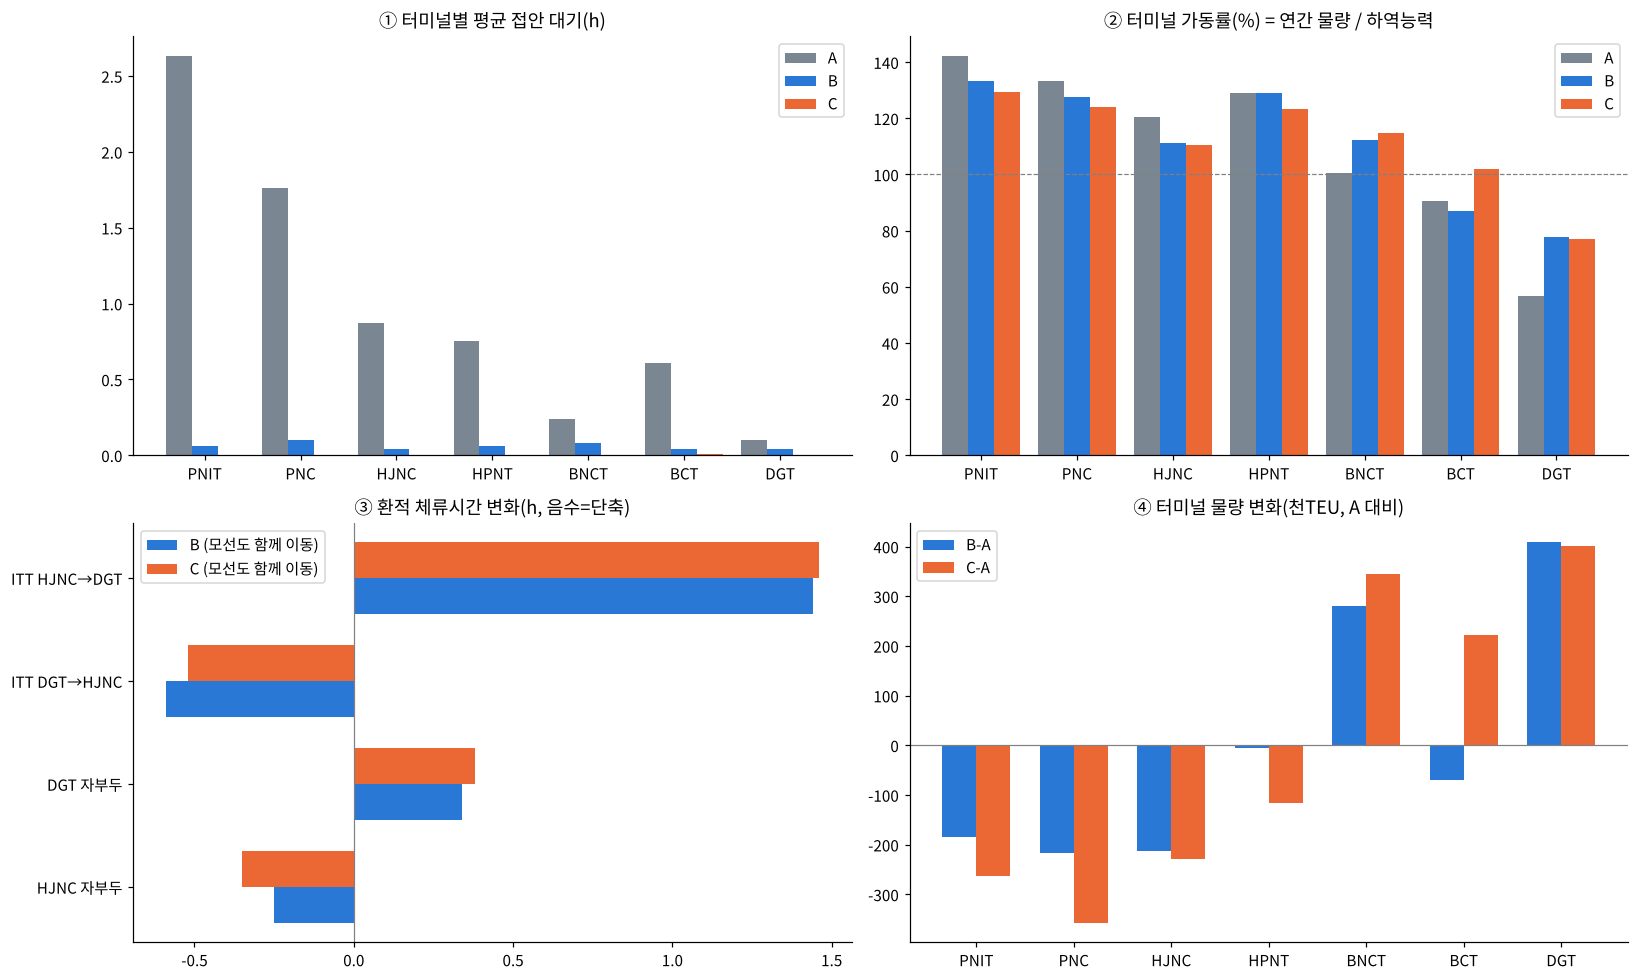

In [33]:
# 셀 33: 요약 그림 (4칸)
import matplotlib.pyplot as plt                       # 그래프 라이브러리
plt.rcParams["font.family"] = ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR", "DejaVu Sans"]   # 한글 글꼴(있는 것을 사용)
plt.rcParams["axes.unicode_minus"] = False            # 마이너스 기호 깨짐 방지
COL = {"A": "#7a8793", "B": "#2a78d6", "C": "#eb6834"}   # 시나리오 색
fig, ax = plt.subplots(2, 2, figsize=(15, 9))
ut = summaries[USE_N]["util_cap"]; ld = summaries[USE_N]["load"]; x = np.arange(len(terms)); w = 0.27

for i, k in enumerate(KEYS):                          # ① 터미널별 평균 대기
    ax[0, 0].bar(x + (i - 1) * w, cmp_term[f"{k} 평균대기h"].reindex(terms), w, color=COL[k], label=k)
ax[0, 0].set_xticks(x); ax[0, 0].set_xticklabels(terms); ax[0, 0].set_title("① 터미널별 평균 접안 대기(h)"); ax[0, 0].legend()

for i, k in enumerate(KEYS):                          # ② 터미널 가동률
    ax[0, 1].bar(x + (i - 1) * w, ut[k].reindex(terms), w, color=COL[k], label=k)
ax[0, 1].axhline(100, color="gray", lw=0.8, ls="--"); ax[0, 1].set_xticks(x); ax[0, 1].set_xticklabels(terms)
ax[0, 1].set_title("② 터미널 가동률(%) = 연간 물량 / 하역능력"); ax[0, 1].legend()

grps = list(summary_dwell.index); y = np.arange(len(grps))   # ③ 체류시간 변화 (나) 기준
for i, k in enumerate(["B", "C"]):
    ax[1, 0].barh(y + (i - 0.5) * 0.35, summary_dwell[f"{k}(나) 모선도"], 0.35, color=COL[k], label=f"{k} (모선도 함께 이동)")
ax[1, 0].set_yticks(y); ax[1, 0].set_yticklabels(grps); ax[1, 0].axvline(0, color="gray", lw=0.8)
ax[1, 0].set_title("③ 환적 체류시간 변화(h, 음수=단축)"); ax[1, 0].legend()

for i, k in enumerate(["B-A", "C-A"]):                # ④ 터미널 물량 변화
    ax[1, 1].bar(x + (i - 0.5) * 0.35, ld[k].reindex(terms), 0.35, color=COL[k[0]], label=k)
ax[1, 1].axhline(0, color="gray", lw=0.8); ax[1, 1].set_xticks(x); ax[1, 1].set_xticklabels(terms)
ax[1, 1].set_title("④ 터미널 물량 변화(천TEU, A 대비)"); ax[1, 1].legend()
for a_ in ax.ravel():
    a_.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(OUT_DIR / "sim_summary_ABC.png", dpi=200)
plt.show()


### KPI 정의와 산식 (셀 28b)

결과는 아래 5개 KPI로만 말한다. 산식은 입력이 바뀔 때 변화 방향이 고정되도록 min/max로 상·하한을 둔 형태이며, 셀 28b에서 assert로 검증한다.

| KPI | 산식 | 방향이 고정되는 성질 |
|---|---|---|
| KPI-1 평균 야드 체류 | D̄ = (1/N) Σ D_i | 연결 간격이 길어지면 증가, 짧아지면 감소 |
| KPI-2 평균 야드 상주 박스 | L = Σ D_i / 8760 | D̄와 같은 방향 (리틀의 법칙) |
| KPI-3 앞당김 효과 | c_i(a,g) = min(a, max(0, G_i − g)),  ΔD̄ = (1/N) Σ c_i | a↑ → 감소량 비감소, g↑ → 감소량 비증가, 0 ≤ c_i ≤ a, G_i ≤ g이면 0 |
| KPI-4 묘박지 대기 | h_v = min(H, max(0, min G_i − g)),  야드 단축 = Σ n_v h_v / N,  선박 비용 = Σ h_v | H↑ → 야드 단축·선박 비용 모두 비감소, 총 체류(야드+묘박지)는 보존 |
| KPI-5 통합 효과 | ΔD̄(B,C) = mean(Δc − Δm) | 부호는 데이터가 정하되 식은 고정 |

- G_i: 컨테이너 i의 연결선 간격(h), a: 앞당김(h), g: 최소 연결 간격(h), H: 묘박지 대기 상한(h), n_v: 모선 v의 환적 박스 수
- 앞당김 효과는 연결선이 실제로 앞당겨질 수 있다는 가정 아래의 산술적 상한이다.


### 야드 체류시간 감소효과 (연결선 스케줄 최적화)

연결선을 앞당기되 앞당긴 뒤에도 연결 간격이 24시간 이상 남는 컨테이너만 대상으로 했다. 야드 체류시간은 연결선 간격으로 거의 정해지므로(상관계수 0.999), 앞당긴 시간만큼 체류가 줄어든다.

| 연결선 앞당김 | 평균 체류 | 감소율 | 평균 야드 상주 박스 감소 |
|---|---|---|---|
| 0h (현재) | 227.2h | 0% | 0개 |
| 10h | 217.5h | 4.3% | 약 44개 |
| 24h | 204.3h | 10.1% | 약 104개 |
| 48h | 183.1h | 19.4% | 약 201개 |

- 앞당김 24h 기준 구분별 감소는 HJNC 자부두 22.9h(11.7%), DGT 자부두 22.9h(8.1%), ITT DGT→HJNC 23.3h(8.2%), ITT HJNC→DGT 22.4h(12.6%)로 구간 간 차이가 작다.
- 터미널 통합(B/C)을 함께 적용해도 감소폭 차이는 ±1.5h 이내라, 야드 체류 감소는 통합이 아니라 연결선 스케줄 조정에서 나온다.
- 이 값은 컨테이너별 가정이다. 한 연결선에 실린 모든 컨테이너가 함께 움직이고 선사 운항 계획과 맞아야 하므로 실제 적용 가능한 상한으로 읽는다.

### A/B/C 시나리오별 야드 체류시간 (셀 30)

| 평균 야드 체류(h) | 기존 | A | B | C |
|---|---|---|---|---|
| 통합만 적용 | 227.2 | 227.2 | 227.6 | 227.7 |
| 통합 + 연결선 24h 앞당김 | 227.2 | 204.3 | 204.7 | 204.7 |
| 기존 대비 감소(통합만) | - | 0.0h | -0.45h | -0.49h |
| 기존 대비 감소(통합+앞당김) | - | 22.9h (10.1%) | 22.5h (9.9%) | 22.5h (9.9%) |
| 야드 상주 박스 감소(통합+앞당김) | - | 약 104개 | 약 102개 | 약 102개 |

- **통합(B/C)만으로는 야드 체류가 줄지 않는다.** 구간별로 HJNC 자부두·ITT DGT→HJNC는 0.3~0.6h 줄지만, DGT 자부두와 ITT HJNC→DGT는 0.3~1.5h 늘어 전체 평균은 오히려 0.5h 안팎 늘어난다.
- **감소는 연결선 앞당김에서 나온다.** A/B/C 모두 약 23h(9.9~10.1%) 줄고, 시나리오 간 차이는 0.5h 이내다.
- 따라서 야드 체류시간 감소를 위해 B나 C로 가야 할 이유는 없고, 앞당김은 현행 운영(A)에서도 같은 효과를 낸다. B/C의 근거는 선석 대기·가동률 완화다.
- 전체 환적 39,887건, 기존 평균 야드 상주 박스 약 1,034개 기준이다. 앞당김 24h와 최소 간격 24h는 가정이며 컨테이너별 상한 추정이다.

### 묘박지 대기를 일부러 넣으면? (셀 31)

모선을 묘박지에서 D시간 더 기다리게 해서 반입을 늦추면 연결선과의 간격이 줄어 야드 체류가 줄어든다. 모선의 모든 연결선에 24h 이상 간격이 남도록 대기를 제한했다.

| 대기 상한 | 대기 받는 모선 | 야드 체류 감소 | 감소율 | 추가 모선 대기 | 컨테이너 총 체류(묘박지+야드) |
|---|---|---|---|---|---|
| 6h | 1,076/1,168척 | 5.2h | 2.3% | 6,311선박·시간 | 변화 없음 |
| 12h | 1,076척 | 10.1h | 4.4% | 12,371 | 변화 없음 |
| 24h | 1,076척 | 18.7h | 8.2% | 23,781 | 변화 없음 |
| 48h | 1,076척 | 31.7h | 14.0% | 43,587 | 변화 없음 |

- 야드 체류는 줄지만 컨테이너는 야드에서 묘박지의 모선 위로 기다리는 장소만 옮긴 것이어서 **총 체류시간은 그대로**다. 줄어드는 것은 야드 지표뿐이다.
- 모선과 그 선박의 다른 화물은 그만큼 늦게 접안한다. 24h 대기는 약 2.4만 선박·시간으로, 관측된 박지 대기(132건 × 평균 36.4h, 약 4,800선박·시간)의 5배 안팎이다.
- 같은 야드 체류 감소(약 20h)를 연결선 24h 앞당김은 모선 대기 없이 얻는다(22.9h).
- 따라서 묘박지 대기 투입은 야드 점유 지표를 낮추는 용도 외에는 권하기 어렵다. 반대 방향의 개선(연결선 앞당김)이 우선이다.
- 한계: 모선이 늦게 접안하면서 생기는 선석 점유 변화와 묘박지 수용 능력, 선사 비용은 반영하지 않았다.

# 요약

- **분석 방향:** 결과를 KPI 5개(평균 야드 체류, 상주 박스, 앞당김 효과, 묘박지 대기, 통합 효과)로 고정하고, 방향이 변하지 않는 산식으로만 계산한다. 앞당김 식을 단조식으로 바꾸면서 24h 앞당김 감소가 22.1h에서 22.9h로 바뀌었다.
- **목적:** 2025년 부산 신항 7개 터미널의 선석 운영을 재현하고, 인접 공유(B)·전체 통합(C)이 대기와 환적 체류에 주는 효과를 비교했다.
- **검증:** 접안 시각 82.4% 재현, 터미널 처리율 기사 대비 평균 3.1%p 차이. 다만 실제 박지 대기는 2.2%만 설명한다.
- **선석 부하(개선안 ①):** 평균 대기 A 0.96h → B 0.06h → C 0.00h. B가 C 단축 효과의 약 93~96%를 낸다. 최대 가동률은 142% → 133% → 129%로 낮아지고, PNIT·PNC 물량이 DGT·BNCT로 이동한다. PNIT는 B에서도 133%라 재배분만으로 과부하가 완전히 해소되지는 않는다.
- **환적 체류(개선안 ②):** 체류시간은 연결선 간격으로 거의 정해진다(상관계수 0.999). 터미널 통합으로는 체류가 ±1.5h밖에 바뀌지 않고, 연결선을 24h 앞당기면 평균 체류가 227.2h → 204.3h(-10.1%)로 줄어든다(상한 추정).
- **A/B/C별 야드 체류:** 통합(B/C)만으로는 평균 체류가 0.5h 안팎 늘어 감소 효과가 없고, 연결선 24h 앞당김을 더하면 A 22.9h, B 22.5h, C 22.5h(약 9.9~10.1%)로 시나리오 간 차이가 거의 없다.
- **묘박지 대기 투입:** 모선을 일부러 대기시키면(24h 상한) 야드 체류는 18.7h 줄지만 컨테이너 총 체류는 그대로이고 모선이 약 2.4만 선박·시간을 더 기다린다. 비용이 옮겨질 뿐이라 권장하지 않는다.
- **자부두 환적 확대:** 같은 간격 구간과 같은 선사끼리 비교해도 자부두가 짧지 않아 근거가 없다. 개선안에서는 뺀다.
- **결론 문장:** ① 선석 부하는 인접 터미널 간 재배분(B)으로 완화한다. ② 환적 체류시간은 연결선 스케줄 간격 관리로 줄인다.
- **한계:** 박지 대기 설명력 2.2%, 터미널별 재현 편차, 인접 관계 가정, 크레인·흘수·얼라이언스 미반영, DGT 물량 보정. 절대값보다 A·B·C 상대 비교로 읽는다.

# 시뮬레이션 결과 요약

> 반복 100회 기준(`USE_N = 100`). 500회 원자료로 10·100·500회를 각각 요약했고, 100회와 500회 결과는 거의 같다(수렴).
> 설정: 안벽 길이 여유 0%, 교체 간격 0h, 선석 수 제약 없음. 도착 시각은 포트미스 박지 대기 132건은 실제 입항 시각, 나머지는 계획 접안(ETB).
> A = 터미널별 기존 운영, B = 인접 터미널끼리 선석 공유, C = 7개 터미널 전체 통합.

## 1. 모델 검증 (시나리오 A가 실제를 재현하는가)

| 검증 항목 | 결과 |
|---|---|
| 실제 접안 시각을 0.5h 이내로 재현한 호출 | 82.4% (평균 절대 오차 1.62h) |
| 평균 대기시간 | 관측 0.68h, 시뮬레이션 0.96h |
| 터미널별 처리율 vs 기사 처리율 | 평균 절대 차이 3.1%p (PNIT 142 vs 146, PNC 133 vs 136, HJNC 120 vs 127, HPNT 129 vs 131, BNCT 101 vs 99, BCT 91 vs 87, DGT 57 vs 57) |
| 터미널별 평균 대기 | PNC·PNIT는 시뮬레이션이 과대(PNC 1.81 vs 0.26, PNIT 2.54 vs 0.16), BCT·DGT는 과소(BCT 0.61 vs 1.50, DGT 0.10 vs 0.88) |
| 포트미스 박지 대기 호출 132건 | 관측 평균 대기 36.4h, 시뮬레이션 평균 대기 0.8h → **모델이 설명하는 비율 2.2%** |

설정 민감도(셀 18): 길이 여유 10%, 교체 간격 2h, 선석 수 제약은 어느 것을 켜도 A의 접안 재현율이 87.4%에서 41~78%로 떨어지고 평균 대기가 관측(0.68h)보다 훨씬 커진다. 그래서 기준 설정을 유지했다. 모든 설정에서 B는 C 효과의 대부분(A→B 평균 대기 단축이 A→C 단축의 약 93~96%)을 낸다.

## 2. KPI 비교 (100회)

| KPI | A 기존 | B 인접공유 | C 전체통합 |
|---|---|---|---|
| 평균 대기(h) | 0.96 | 0.06 | 0.00 |
| P95 대기(h) | 6.83 | 0.00 | 0.00 |
| 대기 발생 호출(%) | 11.30 | 1.74 | 0.12 |
| 타부두 이동 호출(%) | 0 | 10.63 | 11.80 |
| 타부두 이동 물량(천TEU) | 0 | 2,520 | 2,602 |
| 평균 선석 이용률(%) | 57.7 | 58.0 | 58.1 |
| 최대 터미널 가동률(%) | 142.1 | 133.3 | 129.5 |
| 터미널 가동률 편차(표준편차 %p) | 27.7 | 20.0 | 16.5 |

| 터미널 | 가동률 A | 가동률 B | 가동률 C | 물량 변화 B-A (천TEU) | 물량 변화 C-A (천TEU) |
|---|---|---|---|---|---|
| PNIT | 142.1 | 133.3 | 129.5 | -184.5 | -263.9 |
| PNC | 133.3 | 127.6 | 123.9 | -216.1 | -357.5 |
| HPNT | 129.2 | 128.9 | 123.2 | -4.7 | -115.7 |
| HJNC | 120.4 | 111.2 | 110.5 | -213.4 | -229.7 |
| BNCT | 100.7 | 112.2 | 114.8 | +280.2 | +344.2 |
| BCT | 90.7 | 87.1 | 102.1 | -70.4 | +222.2 |
| DGT | 56.6 | 77.6 | 77.1 | +408.9 | +400.4 |

- 접안이 0.5h 넘게 앞당겨진 선박: B 1,116척, C 1,151척 / 7,041척, 최대 앞당김 약 42h
- 가동률 = 연간 물량(TEU) / 연간 하역능력. DGT 물량은 결측 69%라 기사 값(연 1,104천TEU)에 맞춰 보정했다.

## 3. 환적 컨테이너: 연결선 간격과 야드 체류시간

(가) 연결선만 접안이 앞당겨질 때 / (나) 모선과 연결선이 모두 앞당겨질 때 평균 체류시간 변화(h, 음수 = 단축)

| 구분 | 컨테이너 | 기존 평균(h) | B (가) | B (나) | C (가) | C (나) |
|---|---|---|---|---|---|---|
| HJNC 자부두 | 1,487 | 196.2 | -0.94 | -0.25 | -1.07 | -0.35 |
| DGT 자부두 | 154 | 281.0 | +0.03 | +0.34 | +0.02 | +0.38 |
| ITT DGT→HJNC | 18,120 | 283.6 | -0.88 | -0.59 | -0.91 | -0.52 |
| ITT HJNC→DGT | 20,126 | 178.3 | -0.04 | +1.44 | -0.09 | +1.46 |

| 구분 | 기존 연결선 간격 평균(h) | 야드 추가 체류 평균(h) | C에서 간격 0.5h 넘게 줄어든 비율 | 늘어난 비율 |
|---|---|---|---|---|
| HJNC 자부두 | 191.0 | 5.2 | 16.8% | 13.6% |
| DGT 자부두 | 278.0 | 3.0 | 0.0% | 9.1% |
| ITT DGT→HJNC | 280.2 | 3.4 | 12.1% | 7.2% |
| ITT HJNC→DGT | 177.1 | 1.2 | 3.2% | 20.1% |

- 연결선 간격 = 연결선 접안 − 모선 접안, 야드 추가 체류 = 체류시간 − 연결선 간격
- **체류시간과 연결선 간격의 상관계수는 0.999**다.

## 4. 자부두 환적 vs 타부두 환적

- 같은 연결선 간격 구간끼리 비교한 체류시간 중앙값(자부두 vs 타부두): 72h 미만 58.7 vs 52.7, 72~120h 104.0 vs 101.3, 120~168h 149.2 vs 144.0, 168~240h 203.2 vs 203.9, 240h 이상 330.0 vs 339.4
- 같은 선사끼리 비교(양쪽 30건 이상 5개 선사)에서 자부두가 더 짧은 선사는 1곳뿐이다 (HLC +89.7h, HMM -18.5h, ONE -45.4h, SML -19.1h, YML -1.9h: 타부두 − 자부두).


# 결과 분석

## 1. 모델은 "공간 때문에 생기는 대기"만 설명한다
- 접안 재현율 82.4%, 처리율 기사 대비 오차 3.1%p로 전체 운영의 뼈대는 현실과 가깝다.
- 하지만 포트미스 박지 대기 132건의 평균 36.4h 중 모델이 설명하는 것은 2.2%(0.8h)뿐이다. 실제 박지 대기는 안벽에 자리가 없어서가 아니라 선석 계획, 선사 요청, 수심·조석, 작업 준비 등 다른 요인으로 생긴 것으로 보인다.
- 따라서 이 시뮬레이션이 보여 주는 단축 효과는 **"안벽 공간 부족으로 인한 대기"로 한정**되며, 실제 박지 대기 전체를 줄일 수 있다는 근거는 아니다.

## 2. 인접 공유(B)만으로 통합(C) 효과의 대부분을 얻는다
- 평균 대기 0.96h → B 0.06h, C 0.00h. 대기 발생 호출은 11.3% → B 1.7%, C 0.1%.
- 타부두 이동 호출은 B 10.6%, C 11.8%로 거의 같다. 전체 통합까지 가지 않아도 인접 터미널끼리의 공유로 효과 대부분이 나온다.
- 터미널 간 부하 편차는 A 27.7%p → B 20.0%p → C 16.5%p로 줄고, 최대 가동률도 142% → 133% → 129%로 낮아진다. 가동률이 가장 높은 PNIT·PNC에서 물량이 빠져 여유가 있는 DGT(+409천TEU)·BNCT(+280천TEU)로 이동한다.
- DGT 가동률은 56.6%에서 77.6%로 올라도 하역능력(1,950천TEU) 안에 있다. 이전에 DGT 과부하를 우려한 것은 현재 처리량과 비교한 것이었고, 하역능력 대비로는 수용 가능한 범위다.
- 따라서 **① 선석 부하는 터미널 간 재배분(특히 인접 터미널 공유)으로 완화할 수 있다**는 결론은 시뮬레이션으로 뒷받침된다.

## 3. 환적 체류시간은 선석 통합으로 거의 줄지 않는다
- 체류시간 변화는 -1.07h ~ +1.46h로, 기존 180~280h 대비 ±0.6% 이내다.
- 모선과 연결선이 같은 폭으로 앞당겨지면 상쇄된다(HJNC 자부두 (가) -0.94h → (나) -0.25h). 연결선 쪽 터미널(DGT)이 이미 대기가 없었으면 모선만 앞당겨져 체류가 늘어난다(ITT HJNC→DGT (나) +1.44h).
- 선석 통합은 연결선 간격을 0.5h 넘게 줄여 주는 컨테이너가 3~17%뿐이고, 오히려 늘리는 경우도 7~20%다.

## 4. 체류시간은 사실상 연결선 스케줄 간격이고, 앞당기면 야드 체류가 줄어든다
- 체류시간과 연결선 간격(연결선 접안 − 모선 접안)의 상관계수가 0.999다. 야드 추가 체류(체류시간 − 간격)는 평균 1~5h로, 체류시간의 2% 이내다.
- 즉 컨테이너는 야드에서 오래 쌓여 있어서가 아니라, **연결선이 모선보다 며칠 뒤에 들어오기 때문에** 오래 체류한다.
- 연결선을 앞당기되 최소 연결 간격 24h를 남기는 조건으로 계산하면(셀 29), 평균 체류는 227.2h에서 10h 앞당김 217.5h(-4.3%), 24h 앞당김 204.3h(-10.1%), 48h 앞당김 183.1h(-19.4%)가 된다. 평균 야드 상주 박스는 각각 약 44개, 104개, 201개 줄어든다.
- 구간별 감소폭 차이는 작고(24h 기준 22.4~23.3h), 터미널 통합(B/C)을 함께 적용해도 차이는 1.5h 이내다. 감소는 통합이 아니라 스케줄 조정에서 나온다.
- 이 값은 컨테이너별로 계산한 상한이다. 연결선의 모든 컨테이너가 함께 움직이고 선사 운항 계획과 맞아야 한다.

### KPI 산식 기준 읽는 법
- KPI-3 `c_i = min(a, max(0, G_i − g))`: 앞당김 a가 늘면 감소량은 줄지 않고, 최소 간격 g가 늘면 감소량은 늘지 않는다. 따라서 다른 데이터(간격 분포, a, g)를 넣어도 방향이 뒤집히지 않고 크기만 변한다.
- KPI-4 묘박지 대기: 상한 H가 늘수록 야드 단축과 모선 비용이 함께 늘고, 총 체류는 보존된다. 즉 야드 지표 개선은 비용 이동이다.
- KPI-5 통합 효과는 식은 고정이고 부호만 데이터가 정한다. 이번 데이터에서는 B/C 모두 평균 체류가 0.5h 안팎 늘었다.

## 5. 자부두 환적 확대는 이 데이터로 뒷받침되지 않는다
- 같은 연결선 간격 구간끼리 비교하면 자부두와 타부두(ITT)의 체류시간 중앙값이 거의 같다(예: 168~240h 구간 203.2h vs 203.9h). 야드 추가 체류는 오히려 자부두가 조금 더 길다(3.7~6.9h vs 1.4~4.3h).
- 같은 선사끼리 비교해도 자부두가 일관되게 짧지 않다(5개 선사 중 1개만 자부두가 짧음).
- 따라서 "자부두 환적 확대로 체류시간을 줄인다"는 제안은 근거가 약하다. 환적 방식(자부두/타부두)보다 **연결선 스케줄 간격**이 체류시간을 결정한다.

## 6. 개선 방향
1. **선석 부하는 인접 터미널 간 재배분으로 완화한다.** 효과 대부분을 B(인접 공유)에서 얻고, 이동 호출은 약 11%이며 DGT·BNCT가 수용한다.
2. **환적 체류시간은 연결선 스케줄 간격 관리로 줄인다.** 체류시간의 98% 이상이 연결선 간격이므로, 연결선을 24h 앞당기면 평균 체류가 약 10%(22.9h) 줄어든다(KPI-3, 상한 추정). 묘박지 대기 투입은 총 체류를 줄이지 못하므로 쓰지 않는다.
3. 자부두 환적 확대는 이 분석에서 효과가 확인되지 않아 근거로 쓰지 않는다.

# 한계

## 데이터 한계
1. **도착 시각(ETA·ATA) 자료가 없다.** 박지 대기 132건만 포트미스 실제 입항 시각을 반영했고, 나머지는 계획 접안(ETB)을 도착 시각으로 썼다.
2. **DGT 물량 69% 결측.** 중앙값으로 채운 뒤 기사 값(월 9.2만 TEU, 연 1,104천TEU)에 맞춰 보정했다. DGT 길이 매칭은 89.8%다.
3. 환적 분석은 HJNC와 DGT만 가능하다. DGT 자부두 환적은 154건으로 표본이 작고, 비컨테이너선(준설선 등)이 일부 포함되어 있다.

## 모델 한계
1. **실제 박지 대기를 설명하지 못한다.** 박지 대기 132건 평균 36.4h 중 모델이 설명하는 것은 2.2%다. 단축 효과는 "안벽 공간 부족으로 인한 대기"로 한정된다.
2. **터미널별 대기 재현이 고르지 않다.** PNC·PNIT는 과대, BCT·DGT는 과소다. 선석 수 제약, 길이 여유, 교체 간격은 켜면 재현율이 떨어져 기준 설정에서 껐다.
3. **크레인 생산성, 흘수, 얼라이언스·선사 계약, 터미널 전환 비용, 야드 장치능력을 반영하지 않았다.** 가동률이 100%를 넘는 터미널이 있어 공칭 하역능력 기준의 가동률은 근사값이다.
4. **인접 관계는 가정이다.** B는 알려 준 터미널 고리 구조를 썼다. 실제 인접 관계가 다르면 B 결과가 달라질 수 있다.

## 환적·야드 분석 한계
1. **연동 가정.** 반입은 모선 접안, 반출은 연결선 접안과 같은 폭으로 움직인다고 가정했다. 통합으로 타부두 환적이 자부두 환적으로 바뀌는 효과는 반영하지 않았다.
2. **연결선 앞당김은 컨테이너별 상한 추정이다.** 연결선 단위 제약, 선사 운항 일정, 최소 연결 간격(24h는 가정)을 실제 값으로 검증하지 않았다.
3. **야드 장치량과 혼잡은 모델링하지 않았다.** 체류시간 감소를 박스·시간으로만 환산했고, 야드 용량이나 반출입 지연은 고려하지 않았다.
4. 연결선 우선 접안, 선사별 공유 제한 B 변형은 아직 시뮬레이션하지 않았다.

## 산식 한계
1. KPI-3·4는 컨테이너별 간격 G_i와 최소 간격 g, 앞당김 a를 입력으로 하는 산술식이라 모델이 검증한 결과가 아니다. 방향은 고정되지만 크기는 g 가정에 따라 12h 23.5h, 24h 22.9h, 48h 21.3h로 달라진다.
2. 식은 연결선 단위 제약을 반영하지 않는다.

## 해석 시 주의
- 절대값(대기시간, 단축 시간)보다 A·B·C 사이의 상대 비교로 읽는다.
- 자부두 환적 확대에 대한 결론은 "근거 없음"이며, 효과가 없다는 증명은 아니다.